<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/26_QML_Model_Extraction_Theft/QNN_ModelExtraction_Fu2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QNN model extraction under varying noise: CopyQNN (Fu et al., 2025) step by step

This notebook re-implements, runs and checks the attack of

> Zhenxiao Fu, Leyi Zhao, Xuhong Zhang, Yilun Xu, Gang Huang and Fan Chen,
> "CopyQNN: Quantum Neural Network Extraction Attack under Varying Quantum Noise",
> arXiv:2504.00366 [quant-ph], 1 April 2025. https://arxiv.org/abs/2504.00366

The paper publishes no code. Everything below is written from the method as the paper describes it.

**What the notebook does.** A *victim* quantum neural network (QNN) is trained and "deployed" as a QNN-as-a-Service (QNNaaS)
whose cloud NISQ machine is noisy, and whose noise changes during the day. An attacker who can only send images and read back
output probabilities steals a copy of the model in three steps: (1) send a few images at several times of the day and
measure how much each answer fluctuates (*noise characterisation*), (2) throw away the answers that look unreliable
(*data cleaning* with the Remember Ratio RR, plus mixup), (3) train a small *quantum classifier* on top of a *quantum encoder*
that was pre-trained without labels on other images with *Barlow Twins contrastive learning* (*quantum transfer learning*).
It is compared with two baselines of the paper: **Base** (one QNN on all queried data) and **QuantumLeak** (an ensemble of five
QNNs with bagging and majority vote). Everything is simulated: the quantum circuits are simulated exactly with PyTorch (so that
we can train them), and the *cloud* is a **Qiskit Aer** density-matrix simulation with a noise model whose parameters drift over
a 24-hour "day" (the paper used the real 127-qubit IBM_Brisbane).

**How to run it.** Open in Colab (badge above), choose a *CPU* runtime and use *Runtime -> Run all*. The first cell installs
pinned packages; if Colab asks to restart the session, restart and run all again. No GPU, no IBM account and no
paid service is needed. Set `FAST_MODE = False` in the configuration cell for the full experiment.

**Runtime.** `FAST_MODE = True` (5 of the 10 tasks, 1 seed, 100 extra queries for the baselines, shortened training) takes about 6-10 minutes on a CPU. `FAST_MODE = False` (all ten tasks m01...m89 and f01...f89, 3 seeds, 66000 simulated cloud queries, the paper's training budgets scaled to a CPU) took 59 minutes on an 8-core PC that was shared with other jobs; plan for 1.5-2 hours on a 2-core Colab CPU (the Qiskit Aer queries of Sections 4, 5, 7 and 8 take about half of it). The outputs stored in this notebook come from the full run.

**What you get at the end.** The paper's preliminary study (accuracy fluctuation of the victim during the day), the data-cleaning
statistics (Fig. 4), the contrastive-learning loss curves (Fig. 6), the main comparison Base / QuantumLeak / CopyQNN
for the Remember Ratios 0.1 ... 1.0 (Table III), the query-round study (Fig. 7), the design-overhead table (Table II), classical
baselines on the same stolen data, and a side-by-side comparison with every number the paper reports, with a verdict per claim.

## The paper in one page

**Problem.** QNNs deployed as a cloud service are valuable intellectual property. An adversary can *steal* one by querying it
and training a local substitute on the (input, output) pairs (*model extraction*). Earlier QNN extraction work (QuantumLeak)
ignored that NISQ noise **changes during the day**, so labels returned at different times are inconsistent; it also needs
6000 queries (about 18000 labels), which is expensive on an IBM machine and conspicuous to the provider.

**Threat model.** Black box. The attacker knows only the data domain (images). The service returns the raw output probability
vector of each query; the attacker may query many times, but too many queries are suspicious.

**Victim.** For each task a 4-qubit QNN: amplitude encoding of the image, two VQC layers, a measurement layer; trained
noise-free (NLL loss, Adam 5e-3, weight decay 1e-4, batch 32, 30 epochs) on 3000 labelled images, tested on 1000. One VQC
layer = RZ-RY-RZ on every qubit followed by CRX gates between neighbouring qubits (Fig. 5c).

**CopyQNN attack.**
1. *Multi-round query*: the same unlabelled images are sent in m = 5 rounds spread over 24 h (every 24/m hours).
2. *Noise characterisation* (Eq. 1-3): for image i and class j, the m probabilities form a vector P_ij; the image's score is
   var_i = (1/d) * sum_j var(P_ij).
3. *Data cleaning*: rank images by variance in descending order and keep the top fraction RR (*Remember Ratio*). Low variance
   means "consistently wrong" (Fig. 4), so the high-variance images are kept. Mixup is applied on the kept data.
4. *Quantum contrastive knowledge transfer*: a quantum encoder QEnc (8 qubits, amplitude encoding of a 16x16 image, 4 VQC layers,
   Pauli-Z read-out -> 8-dim embedding) is trained with the Barlow Twins loss (Eq. 4) on unlabelled images of *another* task
   (data augmentation: jitter / rotation / crop / flip, with or without Gaussian blur or noise; batch 256, lr 5e-3, weight
   decay 1e-4, 100 epochs). Then QEnc is frozen and a small 4-qubit quantum classifier QClassifier is trained on the cleaned
   queries (cross entropy, lr 5e-2, 300 epochs, batch = all queried images).
5. Table II: CopyQNN needs 40 images x 5 rounds = **200 labels** against QuantumLeak's 6000 x 3 = **18000** (90x fewer queries),
   with 144 single-qubit-gate and 48 two-qubit-gate parameters against 120 and 40 (about +20 % hardware cost).

**Data.** MNIST digit pairs m01, m23, m45, m67, m89 and Fashion-MNIST pairs f01 (t-shirt/trouser), f23 (pullover/dress),
f45 (coat/sandal), f67 (shirt/sneaker), f89 (bag/ankle boot). Metric: test accuracy of the substitute.

**Claims that this notebook checks.**

| # | Claim in the paper | Where |
|---|---|---|
| C1 | Victim f01 (4 qubits) reaches 97.8 % noise-free, but only 72.6 ... 86.6 % when run at five times of the day on IBM_Brisbane (79.2, 80.5, 72.6, 79.6, 86.6) | Sec. III, Fig. 2(a) |
| C2 | On f01 the naive Base reaches 63 % and QuantumLeak 52.4 % (worse than Base) with 5 query rounds | Fig. 2(b) |
| C3 | Wrongly labelled samples sit at low variance; keeping the top 60 % raises the clean share on m01/m23/f01/f23 from 87.1/63.1/76.0/68.1 % to 96.0/69.7/83.5/77.2 % | Fig. 4 |
| C4 | The contrastive loss converges for every augmentation; Gaussian noise raises it slightly; no big differences between augmentations | Fig. 6 |
| C5 | CopyQNN accuracy grows with the number of query rounds: 72.34, 74.60, 83.77, 84.99, 87.40 % for 2, 4, 10, 20, 40 rounds | Fig. 7 |
| C6 | Table III: per-task accuracies of Base, QuantumLeak and CopyQNN for RR = 0.1 ... 1 | Table III |
| C7 | RR = 0.6 is best on average: +8.73 points over QuantumLeak (+29 points on m67); with RR = 1 (no cleaning) many tasks are worse than QuantumLeak | Sec. VI |
| C8 | Design overhead: 200 vs 18000 labels (90x), 144/48 vs 120/40 gate parameters (+20 %) | Table II |

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Quantum hardware | 127-qubit IBM_Brisbane, queries at 5 times in 24 h | Qiskit Aer density-matrix simulation with drifting noise (depolarising, amplitude damping, asymmetric read-out, coherent RY over-rotation); one global noise scale `NOISE_LEVEL` is **calibrated once on the f01 victim** so that its five-time mean accuracy matches the paper's 79.7 % (`# CHOICE`) |
| State preparation on the cloud | amplitude encoding compiled by BQSKit | ideal `set_statevector` followed by one noisy `id` gate per qubit that stands for the compiled encoding circuit (`# CHOICE`) |
| Victim | 4 qubits, amplitude encoding, 2 VQC layers, measurement layer, "QNN zoo of QuantumLeak" | same sizes; input = 28x28 image average-pooled to 4x4 (16 amplitudes); read-out `<Z>` of qubits 0+1 vs 2+3 gives two class scores (`# CHOICE`, the paper does not say) |
| VQC block | RZ-RY-RZ per qubit, then CRX between neighbours (Fig. 5c) | same; CRX gates form a ring (qubit 3 -> 0 closes it), which is what the parameter counts of Table II (40 / 48) imply |
| Victim training | NLL, Adam 5e-3, wd 1e-4, batch 32, 30 epochs, 3000 train / 1000 test | same (FAST: fewer epochs) |
| Attacker's query images | 40 images "from public sources" | 40 images of the two task classes from the held-out part of the training split (never used by the victim) |
| Query rounds / schedule | m = 5, every 24/m hours | same, `h_k = 24 k / m` |
| Variance, RR cleaning | Eq. 3, keep top RR by variance | same |
| Mixup | applied to the remaining labels, no details | mixup of (embedding, probability vector) pairs, Beta(0.4, 0.4) (`# CHOICE`) |
| QEnc | 8 qubits, 4 layers, amplitude encoding of 16x16 images, Barlow Twins, batch 256, lr 5e-3, wd 1e-4, 100 epochs | same architecture and Adam; **40 epochs on 512 unlabelled images** (FAST: 8 epochs, 192 images, batch 64) because an 8-qubit PyTorch simulation on a CPU is slow, hence **lr 2e-2** (`# CHOICE`, picked by the lower training loss in a pilot, not by test accuracy); lambda = 0.05 (`# CHOICE`, paper: 0 <= lambda <= 1) |
| Source data for QEnc | "unlabelled subset of a different task, e.g. m01 for m23" | m01 images for every other MNIST task and m23 images for m01; f01 / f23 likewise for Fashion-MNIST (4 encoders instead of 10) |
| Augmentation | jitter (+ Gaussian) chosen after Fig. 6 | jitter + Gaussian noise (sigma 0.1) |
| QClassifier | 4 qubits (4 layers), cross entropy, lr 5e-2, 300 epochs, batch = all | same; the 8-dim embedding is zero-padded to 16 amplitudes for amplitude encoding (`# CHOICE`) |
| Base / QuantumLeak query budget | 6000 images (QuantumLeak) | `N_BIG` images (400 full, 100 fast); labels from 5 rounds as in the preliminary study |
| Base / QuantumLeak training | Adam 5e-3, wd 1e-4, batch 32, 100 epochs | Adam 2e-2, wd 1e-4, batch 128, 50 epochs (`# CHOICE`, for CPU time); QuantumLeak = 5 bagged copies of the victim architecture + majority vote |
| Evaluation | accuracy of the substitute on the 1000 test images | same, plus agreement with the noise-free victim, confusion matrices, RF/SVC substitutes trained on the same stolen data |
| Seeds | not stated | `SEEDS = [42, 43, 44]` (FAST: `[42]`); every seed uses a different simulated "day", different query images and different initialisations |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and PyTorch.
# The pip line runs on Colab (or wherever Qiskit Aer is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_aer") is None or importlib.util.find_spec("huggingface_hub") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-aer==0.17.2" huggingface_hub pyarrow
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit-aer already present; skipping pip install.")

qiskit-aer already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False           # True: class demo in about 10 minutes. False: full experiment (about 1-1.5 h on a 2-core CPU).
SEED      = 42              # CHOICE: the paper gives no seed
IBM_TOKEN = ""              # optional: only the last, optional cell (real IBM hardware) uses it; leave empty to skip

DATA_DIR  = "data"          # cache for the downloaded datasets (relative to the working directory)

# ---- paper settings (kept in both modes) ----
N_QUBITS_VICTIM, N_LAYERS_VICTIM = 4, 2      # victim QNN and Base / QuantumLeak substitutes
N_QUBITS_ENC,    N_LAYERS_ENC    = 8, 4      # quantum encoder QEnc
N_LAYERS_CLF                      = 4        # QClassifier (4 qubits)
N_TRAIN_VICTIM, N_TEST = 3000, 1000          # victim training images / test images per task
N_QUERY   = 40              # CopyQNN: images queried (Table II)
M_ROUNDS  = 5               # query rounds over 24 h
SHOTS     = 1024            # CHOICE: shots per circuit on the simulated cloud
CLF_LR, CLF_WD, MIXUP_ALPHA = 5e-2, 1e-4, 0.4
ENC_LR, ENC_WD, ENC_LAMBDA  = 2e-2, 1e-4, 0.05   # CHOICE: paper lr 5e-3 for 100 epochs; our schedule has 10-50x fewer steps, so a larger lr
TARGET_MEAN_ACC_F01 = 0.797 # mean of the five accuracies of Fig. 2(a): (79.2 + 80.5 + 72.6 + 79.6 + 86.6) / 5

# ---- budgets that depend on the mode ----
if FAST_MODE:
    TASKS        = ["m01", "m23", "m67", "f01", "f23"]
    SEEDS        = [42]
    RR_GRID      = [0.2, 0.4, 0.6, 0.8, 1.0]
    VICTIM_EPOCHS, VICTIM_BS = 12, 64
    N_BIG        = 100                       # images queried for Base / QuantumLeak (x 5 rounds)
    BIG_EPOCHS, BIG_BS, BIG_LR = 30, 128, 2e-2
    CLF_EPOCHS   = 150
    ENC_N_SRC, ENC_BS, ENC_EPOCHS = 192, 64, 8
    CAL_LEVELS, N_CAL_IMAGES, N_CAL_DAYS = [1.5, 2.0, 2.5, 3.0], 100, 2
    FIG4_TASKS, N_FIG4       = ["m01", "m23", "f01", "f23"], 60
    FIG6_TASKS, FIG6_AUGS    = ["m01", "m23"], ["jitter", "crop"]
    SWEEP_ROUNDS, SWEEP_TASKS, SWEEP_SEEDS = [2, 4, 10], ["m23", "f01", "f23"], [42]
else:
    TASKS        = ["m01", "m23", "m45", "m67", "m89", "f01", "f23", "f45", "f67", "f89"]
    SEEDS        = [42, 43, 44]
    RR_GRID      = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    VICTIM_EPOCHS, VICTIM_BS = 30, 32       # paper
    N_BIG        = 400
    BIG_EPOCHS, BIG_BS, BIG_LR = 50, 128, 2e-2
    CLF_EPOCHS   = 300                       # paper
    ENC_N_SRC, ENC_BS, ENC_EPOCHS = 512, 256, 40
    CAL_LEVELS, N_CAL_IMAGES, N_CAL_DAYS = [2.0, 2.5, 3.0, 3.5, 4.0], 200, 3
    FIG4_TASKS, N_FIG4       = ["m01", "m23", "f01", "f23"], 170
    FIG6_TASKS, FIG6_AUGS    = ["m01", "m23"], ["jitter", "rotation", "crop", "flip"]
    SWEEP_ROUNDS, SWEEP_TASKS, SWEEP_SEEDS = [2, 4, 10, 20, 40], TASKS, [42]
assert "f01" in TASKS
print("FAST_MODE =", FAST_MODE, "| tasks:", TASKS, "| seeds:", SEEDS, "| RR grid:", RR_GRID)

FAST_MODE = False | tasks: ['m01', 'm23', 'm45', 'm67', 'm89', 'f01', 'f23', 'f45', 'f67', 'f89'] | seeds: [42, 43, 44] | RR grid: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]


In [3]:
import os, io, time, math, warnings, itertools
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
warnings.filterwarnings("ignore")

import qiskit, qiskit_aer, sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(max(1, min(4, os.cpu_count() or 2)))
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)

print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| torch", torch.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
T_START = time.time()

qiskit 2.5.2 | qiskit-aer 0.17.2 | torch 2.14.1+cpu
numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


## 1. Data: MNIST and Fashion-MNIST digit / garment pairs

The paper builds ten binary tasks: MNIST **m01, m23, m45, m67, m89** (digit pairs) and Fashion-MNIST **f01** (t-shirt vs trouser),
**f23** (pullover vs dress), **f45** (coat vs sandal), **f67** (shirt vs sneaker), **f89** (bag vs ankle boot). For each task the
*victim* is trained on 3000 labelled images and tested on 1000 images (the test split of the dataset).

The datasets come from Hugging Face (`ylecun/mnist`, `zalando-datasets/fashion_mnist`, parquet files) and are cached in
`DATA_DIR`; OpenML is the fallback. The attacker's query images and the encoder's pre-training images are taken from the
**training split beyond the first 3000 images of the task**, which the victim never saw, and the test images are only used
for the final evaluation.

Two image sizes are needed: the victim (4 qubits = 16 amplitudes) sees the image average-pooled to **4x4**; the quantum encoder
(8 qubits = 256 amplitudes) sees it resized to **16x16** with bilinear interpolation (the paper's "bilinear pooling to 16x16").

{'f01': (3000, 9000, 1000), 'f23': (3000, 9000, 1000), 'f45': (3000, 9000, 1000), 'f67': (3000, 9000, 1000), 'f89': (3000, 9000, 1000), 'm01': (3000, 9665, 1000), 'm23': (3000, 9089, 1000), 'm45': (3000, 8263, 1000), 'm67': (3000, 9183, 1000), 'm89': (3000, 8800, 1000)}


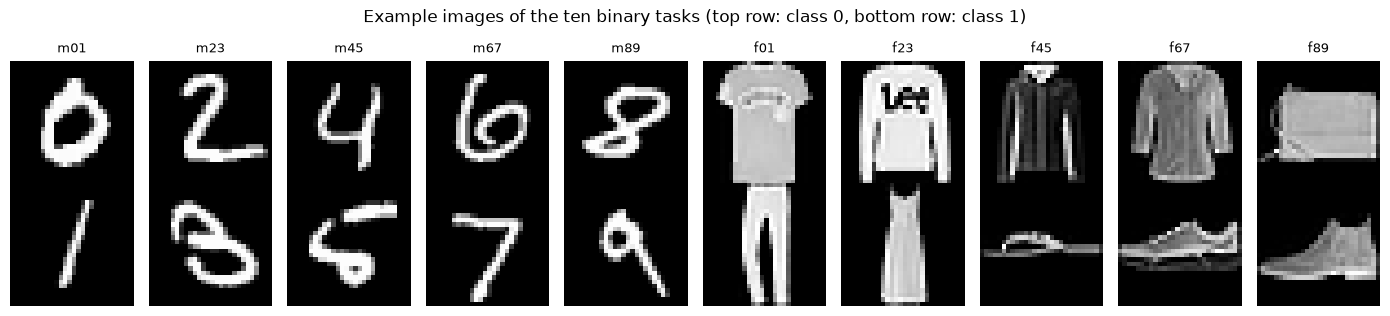

In [4]:
def load_img_parquet(repo, name):
    """Download (cached in DATA_DIR) the Hugging Face parquet files of a 28x28 image dataset -> dict split -> (uint8 images, labels)."""
    import huggingface_hub as hf
    cache = os.path.join(DATA_DIR, f"{name}.npz")
    if os.path.exists(cache):
        z = np.load(cache)
        return {"train": (z["Xtr"], z["ytr"]), "test": (z["Xte"], z["yte"])}
    out = {}
    for split in ["train", "test"]:
        p = hf.hf_hub_download(repo, f"{name}/{split}-00000-of-00001.parquet", repo_type="dataset", local_dir=DATA_DIR)
        d = pd.read_parquet(p)
        X = np.stack([np.array(Image.open(io.BytesIO(b["bytes"]))) for b in d["image"]]).astype(np.uint8)
        out[split] = (X, d["label"].to_numpy())
    np.savez_compressed(cache, Xtr=out["train"][0], ytr=out["train"][1], Xte=out["test"][0], yte=out["test"][1])
    return out

def load_dataset(name):
    """name in {'mnist', 'fashion'}; primary source Hugging Face, fallback OpenML via scikit-learn."""
    repo, fold = {"mnist": ("ylecun/mnist", "mnist"), "fashion": ("zalando-datasets/fashion_mnist", "fashion_mnist")}[name]
    try:
        return load_img_parquet(repo, fold)
    except Exception as e:
        print("Hugging Face download failed (", repr(e)[:80], ") -> OpenML fallback")
        from sklearn.datasets import fetch_openml
        d = fetch_openml({"mnist": "mnist_784", "fashion": "Fashion-MNIST"}[name], version=1, as_frame=False, data_home=DATA_DIR)
        X = d.data.reshape(-1, 28, 28).astype(np.uint8); y = d.target.astype(int)
        return {"train": (X[:60000], y[:60000]), "test": (X[60000:], y[60000:])}

def to_4x4(X):
    """Victim / substitute input: 28x28 -> 7x7 average pooling -> 4x4 = 16 numbers = 16 amplitudes = 4 qubits. (CHOICE)"""
    t = torch.tensor(X, dtype=torch.float32)[:, None] / 255.0
    return F.avg_pool2d(t, 7).reshape(len(X), 16).double()

def to_16x16(X):
    """QEnc input: 28x28 -> bilinear resize to 16x16 = 256 amplitudes = 8 qubits."""
    t = torch.tensor(X, dtype=torch.float32)[:, None] / 255.0
    return F.interpolate(t, size=(16, 16), mode="bilinear", align_corners=False, antialias=True).reshape(len(X), 256).double()

DATASETS = {"mnist": load_dataset("mnist"), "fashion": load_dataset("fashion")}
TASK_DEF = {f"m{a}{a+1}": ("mnist", a, a + 1) for a in (0, 2, 4, 6, 8)}
TASK_DEF.update({f"f{a}{a+1}": ("fashion", a, a + 1) for a in (0, 2, 4, 6, 8)})
FASHION_NAMES = ["t-shirt", "trouser", "pullover", "dress", "coat", "sandal", "shirt", "sneaker", "bag", "ankle boot"]

def task_split(task, split):
    ds, a, b = TASK_DEF[task]
    X, y = DATASETS[ds][split]
    m = (y == a) | (y == b)
    return X[m], (y[m] == b).astype(int)          # label 1 = second class (the "positive" class)

TD = {}                                           # per-task arrays
for t in sorted(set(TASKS) | set(FIG4_TASKS) | set(FIG6_TASKS) | set(SWEEP_TASKS)):
    Xtr, ytr = task_split(t, "train"); Xte, yte = task_split(t, "test")
    TD[t] = dict(Xv=to_4x4(Xtr[:N_TRAIN_VICTIM]), yv=torch.tensor(ytr[:N_TRAIN_VICTIM]),
                 pool_img=Xtr[N_TRAIN_VICTIM:], pool_y=ytr[N_TRAIN_VICTIM:],
                 Xte4=to_4x4(Xte[:N_TEST]), Xte16=to_16x16(Xte[:N_TEST]), yte=torch.tensor(yte[:N_TEST]))
print({t: (len(d["Xv"]), len(d["pool_img"]), len(d["yte"])) for t, d in TD.items()})

fig, ax = plt.subplots(2, 10, figsize=(14, 3.2))
for j, t in enumerate(["m01", "m23", "m45", "m67", "m89", "f01", "f23", "f45", "f67", "f89"]):
    ds, a, b = TASK_DEF[t]; X, y = task_split(t, "test")
    for r, cls in enumerate([0, 1]):
        ax[r, j].imshow(X[np.where(y == cls)[0][0]], cmap="gray"); ax[r, j].axis("off")
    ax[0, j].set_title(t, fontsize=9)
plt.suptitle("Example images of the ten binary tasks (top row: class 0, bottom row: class 1)"); plt.tight_layout(); plt.show()

## 2. The quantum circuits: one simulator for training, one Qiskit twin for the cloud

Training a quantum circuit on a classical computer needs gradients, and Qiskit's primitives are far too slow for thousands of
mini-batches. So the *trainable* circuits are simulated exactly with PyTorch (state-vector arithmetic with automatic
differentiation), and the *cloud* that answers the attacker's queries is simulated with Qiskit Aer. To be sure that the two
describe the same circuit, the check at the end of this section compares them numerically.

**Circuit.** `amplitude encoding -> L x [ RZ(a) RY(b) RZ(c) on every qubit, then CRX(theta) on (0,1), (1,2), ..., (n-1,0) ] -> <Z>
on every qubit`. Amplitude encoding stores the L2-normalised pixel vector (2^n numbers) in the amplitudes of n qubits. Each layer
has 3n single-qubit-gate parameters and n two-qubit-gate (CRX) parameters, the numbers behind Table II.

For registers up to 5 qubits the gates of one circuit are multiplied into a dense 2^n x 2^n unitary (fast), and `BQNN` evaluates
and trains *K independent circuits at once* (a batched matrix product), so that all ten victims, all baselines and all
classifiers of the experiment train in a few big steps. For the 8-qubit encoder the gates are applied one by one to the state.

In [5]:
# ---------- gates (PyTorch, complex128) ----------
def rot_mats(abc):
    """Fused RZ(c) RY(b) RZ(a) for every row of abc (..., 3) -> (..., 2, 2) complex."""
    a, b, c = abc[..., 0], abc[..., 1], abc[..., 2]
    cb, sb = torch.cos(b / 2), torch.sin(b / 2)
    e = lambda x: torch.polar(torch.ones_like(x), x)
    return torch.stack([torch.stack([cb * e(-(a + c) / 2), -sb * e((a - c) / 2)], -1),
                        torch.stack([sb * e((c - a) / 2),  cb * e((a + c) / 2)], -1)], -2)

def crx_mat(theta):
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    rx = torch.stack([torch.stack([c + 0j, -1j * s], -1), torch.stack([-1j * s, c + 0j], -1)], -2)
    return torch.block_diag(torch.eye(2, dtype=rx.dtype), rx)

def amp_encode(x, n):
    """Amplitude encoding: real vectors (B, 2^n) -> normalised state tensor (B,2,...,2) whose axis q+1 is qubit q
    (Qiskit little endian: basis index = sum_q b_q 2^q)."""
    x = x / (x.norm(dim=1, keepdim=True) + 1e-12)
    return x.to(torch.complex128).reshape((-1,) + (2,) * n).permute(0, *range(n, 0, -1))

def apply_1q(psi, U, q):
    return torch.movedim(torch.movedim(psi, q + 1, -1) @ U.T, -1, q + 1)

def apply_2q(psi, M, q0, q1):
    psi = torch.movedim(psi, [q0 + 1, q1 + 1], [-2, -1]); shp = psi.shape
    psi = (psi.reshape(*shp[:-2], 4) @ M.T).reshape(shp)
    return torch.movedim(psi, [-2, -1], [q0 + 1, q1 + 1])

def vqc_apply(psi, params, n):
    """Gate-by-gate version. params: (L, n, 4) = per layer and qubit: (a, b, c) of RZ RY RZ and the angle of the CRX (q -> q+1 mod n)."""
    for l in range(params.shape[0]):
        U = rot_mats(params[l, :, :3]).to(psi.dtype)
        for q in range(n): psi = apply_1q(psi, U[q], q)
        for q in range(n): psi = apply_2q(psi, crx_mat(params[l, q, 3]).to(psi.dtype), q, (q + 1) % n)
    return psi

_ZS = {}
def z_expvals(psi, n):
    """<Z_q> for every qubit from a flat or tensor state (qubit 0 = most significant bit of the flat index)."""
    if n not in _ZS:
        _ZS[n] = torch.tensor([[1 - 2 * ((k >> (n - 1 - q)) & 1) for q in range(n)] for k in range(2 ** n)], dtype=torch.float64)
    return (psi.real ** 2 + psi.imag ** 2).reshape(psi.shape[0], -1).double() @ _ZS[n]

class QNN(nn.Module):
    """One circuit, gate-by-gate simulation (used for the 8-qubit encoder QEnc)."""
    def __init__(self, n, layers, seed):
        super().__init__()
        g = torch.Generator().manual_seed(int(seed)); self.n, self.L = n, layers
        self.params = nn.Parameter((torch.rand(layers, n, 4, generator=g, dtype=torch.float64) * 2 - 1) * math.pi)
    def forward(self, x):
        return z_expvals(vqc_apply(amp_encode(x, self.n).to(torch.complex64), self.params.float(), self.n), self.n)

# ---------- K small circuits at once via dense unitaries ----------
_RING = {}
def ring_constants(n):
    """Constant matrices D0, D1, D2 with CRX(theta) = D0 + cos(theta/2) D1 - i sin(theta/2) D2 for control q, target (q+1) mod n."""
    if n in _RING: return _RING[n]
    I2 = torch.eye(2, dtype=torch.complex128); P0 = torch.diag(torch.tensor([1, 0], dtype=torch.complex128))
    P1 = torch.diag(torch.tensor([0, 1], dtype=torch.complex128)); X = torch.tensor([[0, 1], [1, 0]], dtype=torch.complex128)
    def kron_all(ops):
        out = ops[0]
        for o in ops[1:]: out = torch.kron(out, o)
        return out
    D = []
    for c in range(n):
        t = (c + 1) % n
        def build(opc, opt):
            ops = [I2] * n; ops[c] = opc; ops[t] = opt
            return kron_all(ops)
        D.append(torch.stack([build(P0, I2), build(P1, I2), build(P1, X)]))
    _RING[n] = torch.stack(D)
    return _RING[n]

def vqc_unitary_b(params, n):
    """params (K, L, n, 4) -> (K, 2^n, 2^n): the unitaries of K circuits at once (qubit 0 = most significant bit)."""
    D = ring_constants(n); K = params.shape[0]; U = None
    for l in range(params.shape[1]):
        R = rot_mats(params[:, l, :, :3])                                      # (K,n,2,2)
        Kr = R[:, 0]
        for q in range(1, n):
            d = Kr.shape[-1]
            Kr = torch.einsum("kab,kcd->kacbd", Kr, R[:, q]).reshape(K, d * 2, d * 2)
        th = params[:, l, :, 3]
        coef = torch.stack([torch.ones_like(th) + 0j, torch.cos(th / 2) + 0j, -1j * torch.sin(th / 2)], -1)
        ring = torch.einsum("kqc,qcij->kqij", coef, D)
        Ul = Kr
        for q in range(n): Ul = ring[:, q] @ Ul
        U = Ul if U is None else Ul @ U
    return U

def _rev_index(n):
    return torch.tensor([int(format(j, f"0{n}b")[::-1], 2) for j in range(2 ** n)])

class BQNN(nn.Module):
    """K independent small QNNs (amplitude encoding -> L VQC layers -> <Z> on every qubit), evaluated and trained together.
    Adam acts element-wise, so this is identical to training K separate models; it is just much faster in PyTorch."""
    def __init__(self, K, n, layers, seeds):
        super().__init__()
        self.n, self.L, self.K = n, layers, K
        p = [(torch.rand(layers, n, 4, generator=torch.Generator().manual_seed(int(s)), dtype=torch.float64) * 2 - 1) * math.pi for s in seeds]
        self.params = nn.Parameter(torch.stack(p)); self.rev = _rev_index(n)
    def forward(self, x):                                                      # x: (K, B, 2^n) -> (K, B, n)
        x = x / (x.norm(dim=-1, keepdim=True) + 1e-12)
        psi = torch.einsum("kbi,kji->kbj", x[..., self.rev].to(torch.complex128), vqc_unitary_b(self.params, self.n))
        return z_expvals(psi.reshape(-1, 2 ** self.n), self.n).reshape(x.shape[0], x.shape[1], self.n)

def head(z):
    """Measurement layer of victim and substitutes: <Z> of qubits {0,1} summed -> class-0 score, qubits {2,3} -> class-1 score."""
    return z.reshape(*z.shape[:-1], 2, -1).sum(-1)

def n_params(n, L):
    return 3 * n * L, n * L                       # (single-qubit-gate parameters, two-qubit-gate parameters)

def pad_stack(Xs, Ys):
    """Lists of per-model data -> padded tensors (K,N,d), (K,N,2) and a weight mask (K,N)."""
    K, N, d = len(Xs), max(len(x) for x in Xs), Xs[0].shape[1]
    X = torch.zeros(K, N, d, dtype=torch.float64); Y = torch.zeros(K, N, 2, dtype=torch.float64); W = torch.zeros(K, N)
    for k in range(K):
        n = len(Xs[k]); X[k, :n] = Xs[k]; Y[k, :n] = Ys[k]; W[k, :n] = 1
    return X, Y, W

def train_batched(model, X, Y, W, epochs, bs, lr, wd, seed, mixup_alpha=0.0, hist=None):
    """Train the K circuits of a BQNN simultaneously, each on its own data X[k] with soft labels Y[k] and row mask W[k].
    Soft-label cross-entropy (= negative log-likelihood for one-hot labels), Adam(lr, weight_decay=wd), optional mixup,
    an independent random batch order per model."""
    torch.manual_seed(int(seed))
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    K, N = X.shape[:2]; nvalid = W.sum(1)
    beta = torch.distributions.Beta(mixup_alpha, mixup_alpha) if mixup_alpha > 0 else None
    steps = int(math.ceil(nvalid.max().item() / bs)); ar = torch.arange(K)[:, None]
    for ep in range(epochs):
        order = torch.argsort(torch.rand(K, N) + (1 - W) * 10, dim=1)           # valid rows first, random order per model
        tot = 0.0
        for s in range(steps):
            idx = order[:, s * bs:(s + 1) * bs]
            if idx.shape[1] == 0: break
            xb, yb, wb = X[ar, idx], Y[ar, idx], W[ar, idx]
            if beta is not None:
                lam = beta.sample((K, idx.shape[1], 1)).double()
                j = (torch.rand(K, idx.shape[1]) * nvalid[:, None]).long().clamp(max=N - 1)   # partner among the model's own samples
                jj = order[ar, j]
                xb = lam * xb + (1 - lam) * X[ar, jj]; yb = lam * yb + (1 - lam) * Y[ar, jj]
            ce = -(yb * F.log_softmax(head(model(xb)), -1)).sum(-1)
            loss = ((ce * wb).sum(1) / wb.sum(1).clamp(min=1)).sum()
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item()
        if hist is not None: hist.append(tot / steps / K)
    return model

def predict_logits(model, Xk):
    with torch.no_grad(): return head(model(Xk))

### 2b. Check: the PyTorch circuits are the same circuits as the Qiskit ones

`var_circuit` builds the variational part of the circuit in Qiskit (RZ, RY, RZ, then CRX gates, exactly the gates the paper
draws in Fig. 5c). We compare `<Z_q>` computed by Qiskit's exact `Statevector` with the PyTorch value for random parameters
and random images, for the 4-qubit victim circuit (dense-unitary path), the 4-qubit gate-by-gate path and the 8-qubit encoder.

In [6]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, SparsePauliOp

def var_circuit(params, n):
    """Qiskit version of vqc_apply: RZ(a) RY(b) RZ(c) on each qubit, then the CRX ring."""
    qc = QuantumCircuit(n)
    for l in range(params.shape[0]):
        for q in range(n):
            a, b, c = params[l, q, :3]
            qc.rz(float(a), q); qc.ry(float(b), q); qc.rz(float(c), q)
        for q in range(n):
            qc.crx(float(params[l, q, 3]), q, (q + 1) % n)
    return qc

def qiskit_z(x, params, n):
    qc = QuantumCircuit(n); qc.initialize(x / np.linalg.norm(x), range(n)); qc.compose(var_circuit(params, n), inplace=True)
    sv = Statevector(qc)
    return np.array([sv.expectation_value(SparsePauliOp("I" * (n - 1 - q) + "Z" + "I" * q)).real for q in range(n)])

rg = np.random.default_rng(SEED)
x4 = torch.tensor(rg.random((3, 16)))
bm = BQNN(1, 4, 2, [7]); z_dense = bm(x4[None])[0].detach().numpy()
z_state = z_expvals(vqc_apply(amp_encode(x4, 4), bm.params[0], 4), 4).detach().numpy()
err_dense = max(np.abs(qiskit_z(x4[i].numpy(), bm.params[0].detach().numpy(), 4) - z_dense[i]).max() for i in range(3))
err_state = max(np.abs(qiskit_z(x4[i].numpy(), bm.params[0].detach().numpy(), 4) - z_state[i]).max() for i in range(3))
x8 = torch.tensor(rg.random((2, 256))); enc = QNN(8, 4, 3); z8 = enc(x8).detach().numpy()
err_8q = max(np.abs(qiskit_z(x8[i].numpy(), enc.params.detach().numpy(), 8) - z8[i]).max() for i in range(2))
print(f"max |Qiskit - PyTorch| of <Z>:  4 qubits dense unitary {err_dense:.1e} | 4 qubits gate-by-gate {err_state:.1e} | 8 qubits (float32) {err_8q:.1e}")
assert err_dense < 1e-8 and err_state < 1e-8 and err_8q < 1e-4
print("The PyTorch circuits and the Qiskit circuits agree.")

max |Qiskit - PyTorch| of <Z>:  4 qubits dense unitary 5.4e-13 | 4 qubits gate-by-gate 5.4e-13 | 8 qubits (float32) 1.3e-07
The PyTorch circuits and the Qiskit circuits agree.


## 3. The victim QNNs (trained noise-free by their owner)

Each task gets its own victim: 4 qubits, amplitude encoding of the 4x4 image, two VQC layers, measurement layer (the class-0
score is `<Z_0> + <Z_1>`, the class-1 score `<Z_2> + <Z_3>`, followed by a softmax). Training follows the paper: negative
log-likelihood, Adam with learning rate 5e-3 and weight decay 1e-4, batch size 32, 30 epochs, 3000 training images (FAST mode
shortens this). All victims train in one batched run. The owner trains on an ideal simulator, so the accuracy below is the
paper's "ideal" accuracy.

The paper reports an ideal accuracy of 97.8 % for f01. A 4x4 image only has 16 numbers, and even a logistic regression on the
same 4x4 inputs stays near 93 % on f01 (see the exercises), so a lower number is expected here.

trained 10 victims in 126 s (epochs=30, batch=32)
                                 f01   f23   f45   f67   f89   m01   m23   m45   m67   m89
ideal victim test accuracy (%)  93.7  95.0  99.5  99.6  99.1  92.7  87.6  94.4  96.4  88.5


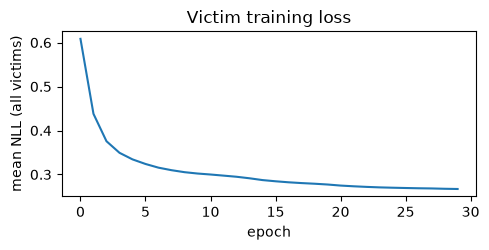

In [7]:
t0 = time.time()
VTASKS = list(TD)
Xs, Ys, Ws = pad_stack([TD[t]["Xv"] for t in VTASKS], [F.one_hot(TD[t]["yv"], 2).double() for t in VTASKS])
victims = BQNN(len(VTASKS), N_QUBITS_VICTIM, N_LAYERS_VICTIM, [SEED + 7 * i for i in range(len(VTASKS))])
vhist = []
train_batched(victims, Xs, Ys, Ws, VICTIM_EPOCHS, VICTIM_BS, 5e-3, 1e-4, SEED, hist=vhist)
Xte_all = torch.stack([TD[t]["Xte4"] for t in VTASKS])
ideal_logits = predict_logits(victims, Xte_all)
VIC = {}
for i, t in enumerate(VTASKS):
    pred = ideal_logits[i].argmax(1)
    VIC[t] = dict(params=victims.params[i].detach().numpy().copy(), ideal_pred=pred, ideal_acc=(pred == TD[t]["yte"]).double().mean().item())
print(f"trained {len(VTASKS)} victims in {time.time() - t0:.0f} s (epochs={VICTIM_EPOCHS}, batch={VICTIM_BS})")
print(pd.Series({t: round(VIC[t]["ideal_acc"] * 100, 1) for t in VTASKS}, name="ideal victim test accuracy (%)").to_frame().T.to_string())
plt.figure(figsize=(5, 2.6)); plt.plot(vhist); plt.xlabel("epoch"); plt.ylabel("mean NLL (all victims)"); plt.title("Victim training loss"); plt.tight_layout(); plt.show()

## 4. The simulated QNN-as-a-Service: a noisy cloud whose noise drifts during the day

The paper queries IBM_Brisbane at five times of the day and observes that the same circuit gives different accuracy (Table I,
Fig. 2a). We have no hardware, so the cloud is a **Qiskit Aer density-matrix simulation** with a noise model whose parameters
change smoothly over 24 hours (`DeviceDrift`: a few sinusoids with random periods and phases per noise component):

* depolarising error on RY (single-qubit) and CX (two-qubit) gates; RZ is a virtual gate on IBM machines and is noise free,
* amplitude damping (T1-like) after the gates and after state preparation, which pushes qubits towards |0>,
* asymmetric read-out error `P(1|0) < P(0|1)`,
* a small coherent RY over-rotation per qubit that wanders over the day (the paper cites control imperfections and crosstalk).

State preparation is ideal (`set_statevector`), followed by one noisy `id` gate per qubit that represents the deep circuit
into which amplitude encoding is compiled on real hardware (BQSKit in the paper). The service returns, as in the paper, the
raw output estimated from `SHOTS` measurement shots. A single global scale **`NOISE_LEVEL`** multiplies all noise strengths.
It is the only fitted number of the notebook and is chosen in Section 4b (**`# CHOICE`**) on a few *calibration days* so that
the f01 victim's accuracy over five times of the day averages the paper's 79.7 %. Experiments later run on other simulated days.
In addition, every component has a static part (for example a fixed over-rotation per qubit, the same all day: such errors make
the same images wrong in every round) and a time-dependent part of relative size DRIFT = 0.5.

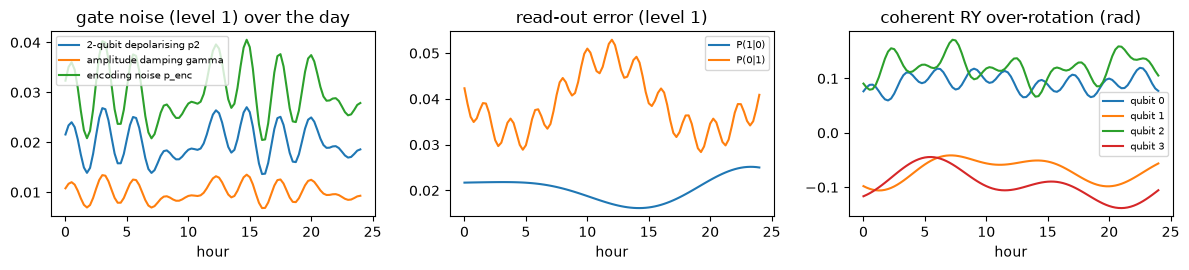

In [8]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import (NoiseModel, depolarizing_error, ReadoutError, amplitude_damping_error, coherent_unitary_error)
from qiskit_aer.library import SetStatevector  # noqa: F401  (registers QuantumCircuit.set_statevector)
from qiskit.quantum_info import Operator
from qiskit.circuit.library import RYGate

CLOUD_BASIS = ["rx", "ry", "rz", "cx", "id"]

class DeviceDrift:
    """One simulated day of a device. Besides a *static* part (a fixed coherent error per qubit, the same all day) every noise
    component drifts smoothly: a few sinusoids (periods 2 h ... 24 h, random phases). value(h, k) is roughly in [-1, 1].
    One seed = one simulated day (different static offsets and different drift)."""
    def __init__(self, seed, n_series=16, n_waves=4):
        g = np.random.default_rng(seed)
        self.per = g.uniform(2.0, 24.0, (n_series, n_waves)); self.ph = g.uniform(0, 2 * np.pi, (n_series, n_waves))
        self.amp = g.uniform(0.3, 1.0, (n_series, n_waves)); self.amp /= self.amp.sum(1, keepdims=True)
        self.static = g.uniform(0.5, 1.0, 8) * g.choice([-1.0, 1.0], 8)
    def value(self, h, k):
        return float((self.amp[k] * np.sin(2 * np.pi * h / self.per[k] + self.ph[k])).sum())

DRIFT = 0.5          # CHOICE: size of the time-dependent part of every noise component relative to its static part

def noise_at(h, day, level, n):
    """Noise parameters of the simulated device at hour h of `day`. CHOICE: base values are typical NISQ orders of magnitude
    times `level`; every component drifts with time by +-DRIFT (relative)."""
    d = lambda k: day.value(h, k)
    s = 1 + DRIFT * d(0)                                                     # overall multiplier of gate noise
    return dict(p1=0.002 * level * s, p2=0.02 * level * s, gamma=0.01 * level * s,
                p_ro01=0.02 * level * (1 + DRIFT * d(1)), p_ro10=0.04 * level * (1 + DRIFT * d(2)), p_enc=0.03 * level * s,
                delta=[0.12 * level * (day.static[q] + DRIFT * d(3 + q)) for q in range(n)])   # coherent RY over-rotation per qubit (rad)
def make_noise_model(nz, n):
    nm = NoiseModel(basis_gates=CLOUD_BASIS + ["set_statevector"])
    ad1 = amplitude_damping_error(min(1.0, nz["gamma"] * 0.5))
    for q in range(n):
        coh = coherent_unitary_error(Operator(RYGate(nz["delta"][q])))
        nm.add_quantum_error(coh.compose(depolarizing_error(nz["p1"], 1)).compose(ad1), ["ry"], [q])
        nm.add_quantum_error(depolarizing_error(nz["p1"], 1), ["rx"], [q])
    ad2 = amplitude_damping_error(min(1.0, nz["gamma"]))
    nm.add_all_qubit_quantum_error(depolarizing_error(nz["p2"], 2).compose(ad2.tensor(ad2)), ["cx"])
    nm.add_all_qubit_quantum_error(depolarizing_error(nz["p_enc"], 1).compose(amplitude_damping_error(min(1.0, nz["gamma"] * 2))), ["id"])
    nm.add_all_qubit_readout_error(ReadoutError([[1 - nz["p_ro01"], nz["p_ro01"]], [nz["p_ro10"], 1 - nz["p_ro10"]]]))
    return nm

def cloud_query(Xamp, params, n, nz, shots, seed, chunk=400):
    """Send images (rows of Xamp, 2^n numbers each) to the simulated QNNaaS: ideal state preparation, noisy variational circuit,
    noisy read-out, `shots` shots. Returns the raw output <Z_q> (N, n) estimated from the counts (nz=None: no gate noise)."""
    var_t = transpile(var_circuit(params, n), basis_gates=CLOUD_BASIS, optimization_level=0)
    backend = AerSimulator(method="density_matrix", noise_model=make_noise_model(nz, n) if nz is not None else None)
    amps = (Xamp / (Xamp.norm(dim=1, keepdim=True) + 1e-12)).numpy().astype(complex)
    out = np.zeros((len(amps), n))
    sgn = np.array([[1 - 2 * ((k >> q) & 1) for q in range(n)] for k in range(2 ** n)])
    for s in range(0, len(amps), chunk):
        circs = []
        for v in amps[s:s + chunk]:
            qc = QuantumCircuit(n, n); qc.set_statevector(v)
            for q in range(n): qc.id(q)
            qc.compose(var_t, inplace=True); qc.measure(range(n), range(n)); circs.append(qc)
        res = backend.run(circs, shots=shots, seed_simulator=int(seed) + s).result()
        for i, c in enumerate(res.get_counts()):
            for key, cnt in c.items(): out[s + i] += cnt * sgn[int(key, 2)]
    return out / shots

def query_cloud(task, images28, day, level, m, qseed):
    """Multi-round query (Sec. IV-B): the same images are sent m times, at hours 24 k / m, k = 0..m-1.
    Returns the softmax probability vectors P with shape (m, N, 2)."""
    X4 = to_4x4(images28); out = []
    for k in range(m):
        raw = cloud_query(X4, VIC[task]["params"], 4, noise_at(24.0 * k / m, day, level, 4), SHOTS, qseed * 1000 + 7 * k)
        out.append(F.softmax(head(torch.tensor(raw)), -1).numpy())
    return np.stack(out)

# ---- the noise profile of one simulated day ----
hh = np.linspace(0, 24, 97); day0 = DeviceDrift(0)
fig, ax = plt.subplots(1, 3, figsize=(12, 2.8))
for key, lab in [("p2", "2-qubit depolarising p2"), ("gamma", "amplitude damping gamma"), ("p_enc", "encoding noise p_enc")]:
    ax[0].plot(hh, [noise_at(h, day0, 1.0, 4)[key] for h in hh], label=lab)
ax[0].set_title("gate noise (level 1) over the day"); ax[0].set_xlabel("hour"); ax[0].legend(fontsize=7)
ax[1].plot(hh, [noise_at(h, day0, 1.0, 4)["p_ro01"] for h in hh], label="P(1|0)"); ax[1].plot(hh, [noise_at(h, day0, 1.0, 4)["p_ro10"] for h in hh], label="P(0|1)")
ax[1].set_title("read-out error (level 1)"); ax[1].set_xlabel("hour"); ax[1].legend(fontsize=7)
for q in range(4): ax[2].plot(hh, [noise_at(h, day0, 1.0, 4)["delta"][q] for h in hh], label=f"qubit {q}")
ax[2].set_title("coherent RY over-rotation (rad)"); ax[2].set_xlabel("hour"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

### 4b. Preliminary study (paper Sec. III, Fig. 2a): the same victim gives different accuracy at different times

We run the f01 victim on the cloud at five evenly spaced times of the day (0, 4.8, 9.6, 14.4, 19.2 h) for several values of
`NOISE_LEVEL` on `N_CAL_DAYS` *calibration days* (different seeds of `DeviceDrift`, because one day can be much luckier or
unluckier than another), and keep the level whose accuracy, averaged over days and times, is closest to the paper's 79.7 %.
Then the five accuracies of a calibration day are plotted next to the paper's. Because the level was fitted to the *mean*,
the interesting outputs are the *spread* over the day (paper: 72.6 ... 86.6 %, i.e. 14 points) and the day-to-day variation.

     mean acc (%)  within-day spread max-min  day 0 mean  day 1 mean  day 2 mean
2.0          84.6                       10.8        75.6        88.8        89.3
2.5          79.8                       10.7        68.0        85.0        86.5
3.0          75.7                       13.8        64.4        80.1        82.6
3.5          71.6                       12.7        63.1        74.0        77.8
4.0          67.0                       10.3        62.3        66.5        72.3

NOISE_LEVEL = 2.5 (closest to the paper's mean of 79.7 %)   [265 s]


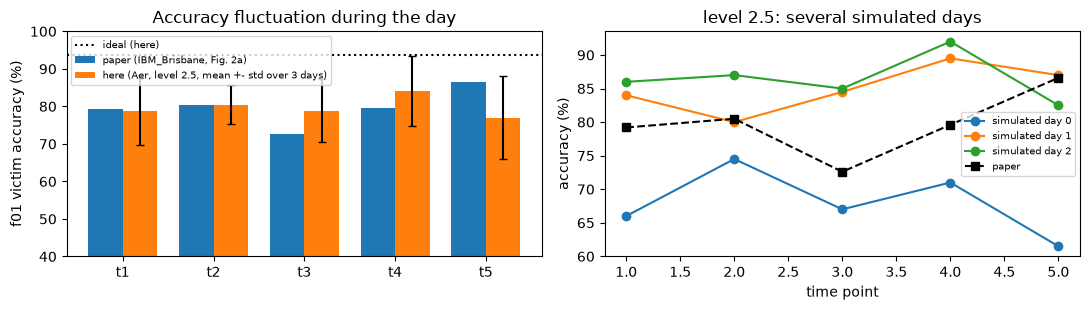

In [9]:
t0 = time.time()
Xc_img = task_split("f01", "test")[0][:N_CAL_IMAGES]; yc = TD["f01"]["yte"][:N_CAL_IMAGES].numpy()
hours5 = [24.0 * k / 5 for k in range(5)]
cal = {}                                                    # level -> accuracies (%) array (days, 5 times)
for lev in CAL_LEVELS:
    per_day = []
    for dseed in range(N_CAL_DAYS):
        day = DeviceDrift(dseed)
        accs = []
        for k, h in enumerate(hours5):
            raw = cloud_query(to_4x4(Xc_img), VIC["f01"]["params"], 4, noise_at(h, day, lev, 4), SHOTS, 900 + k)
            accs.append(100 * (head(torch.tensor(raw)).argmax(1).numpy() == yc).mean())
        per_day.append(accs)
    cal[lev] = np.array(per_day)
cal_df = pd.DataFrame({lev: {"mean acc (%)": a.mean(), "within-day spread max-min": (a.max(1) - a.min(1)).mean(),
                             **{f"day {d} mean": a[d].mean() for d in range(N_CAL_DAYS)}} for lev, a in cal.items()}).T
print(cal_df.round(1).to_string())
NOISE_LEVEL = min(CAL_LEVELS, key=lambda l: abs(cal_df.loc[l, "mean acc (%)"] / 100 - TARGET_MEAN_ACC_F01))   # CHOICE: the single fitted number
print(f"\nNOISE_LEVEL = {NOISE_LEVEL} (closest to the paper's mean of {TARGET_MEAN_ACC_F01 * 100:.1f} %)   [{time.time() - t0:.0f} s]")

PAPER_FIG2A = [79.2, 80.5, 72.6, 79.6, 86.6]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
w = 0.38; xx = np.arange(5)
ax[0].bar(xx - w / 2, PAPER_FIG2A, w, label="paper (IBM_Brisbane, Fig. 2a)"); ax[0].bar(xx + w / 2, cal[NOISE_LEVEL].mean(0), w, yerr=cal[NOISE_LEVEL].std(0), capsize=3, label=f"here (Aer, level {NOISE_LEVEL}, mean +- std over {N_CAL_DAYS} days)")
ax[0].axhline(VIC["f01"]["ideal_acc"] * 100, color="k", ls=":", label="ideal (here)"); ax[0].set_ylim(40, 100)
ax[0].set_xticks(xx); ax[0].set_xticklabels([f"t{i+1}" for i in xx]); ax[0].set_ylabel("f01 victim accuracy (%)"); ax[0].legend(fontsize=7); ax[0].set_title("Accuracy fluctuation during the day")
for d in range(N_CAL_DAYS): ax[1].plot(range(1, 6), cal[NOISE_LEVEL][d], marker="o", label=f"simulated day {d}")
ax[1].plot(range(1, 6), PAPER_FIG2A, "k--s", label="paper"); ax[1].set_xlabel("time point"); ax[1].set_ylabel("accuracy (%)"); ax[1].legend(fontsize=7); ax[1].set_title(f"level {NOISE_LEVEL}: several simulated days")
plt.tight_layout(); plt.show()

## 5. Multi-round query, noise characterisation and data cleaning (paper Sec. IV-B, Fig. 4)

For `n` images sent in `m` rounds, round `t` returns a probability vector `[p_t,i,1, ..., p_t,i,d]` per image (Eq. 1), the
label is its arg-max (Eq. 2). For image `i` and class `j` the `m` probabilities form `P_ij`; the variance score of the image is
`var_i = (1/d) * sum_j var(P_ij)` (Eq. 3). The paper finds that **mislabelled images have low variance**: they are wrong in
every round (the noise pushes them consistently to the wrong class) whereas correctly labelled images fluctuate more.
The *Remember Ratio* `RR` ranks images by variance in descending order and keeps only the top fraction.

The next cell queries `N_FIG4` images of m01, m23, f01 and f23 (paper Fig. 4) in `m = 5` rounds on a fresh simulated day,
draws the variance histograms of correctly and wrongly labelled images, and computes the share of correct round labels among
the kept images for RR = 1 and RR = 0.6. The paper's numbers for the four tasks: 87.1 -> 96.0 %, 63.1 -> 69.7 %, 76.0 -> 83.5 %,
68.1 -> 77.2 %.

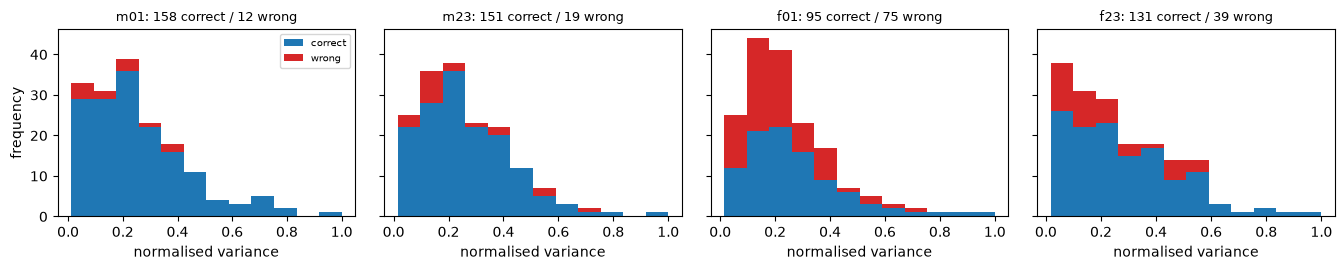

     clean % (RR=1) here  clean % (RR=0.6) here  paper RR=1  paper RR=0.6  mean norm. var correct  mean norm. var wrong
m01               92.471                 93.529        87.1          96.0                   0.262                 0.192
m23               87.059                 88.824        63.1          69.7                   0.267                 0.253
f01               57.765                 64.314        76.0          83.5                   0.273                 0.213
f23               76.588                 82.157        68.1          77.2                   0.286                 0.222
[61 s]


In [10]:
def variance_score(P):
    """Eq. (3). P: (m, N, d) probability vectors of m rounds -> (N,) score var_i = mean_j var over rounds of p_{t,i,j}."""
    return P.var(0).mean(-1)

def remember_ratio_keep(P, rr):
    """Indices of the images kept by the Remember Ratio: highest variance first, keep ceil(rr * N)."""
    return np.argsort(-variance_score(P), kind="stable")[: int(math.ceil(rr * P.shape[1]))]

def clean_share(P, y, keep):
    """Share of correct (image, round) labels among the kept images (the paper's 'proportion of clean samples')."""
    return float((P[:, keep].argmax(-1) == y[keep][None]).mean())

t0 = time.time()
day_fig4 = DeviceDrift(1000)
fig4 = {}
fig, ax = plt.subplots(1, len(FIG4_TASKS), figsize=(3.4 * len(FIG4_TASKS), 2.8), sharey=True, squeeze=False); ax = ax[0]
for i, t in enumerate(FIG4_TASKS):
    g = np.random.default_rng(SEED + 31 * i)
    idx = g.choice(len(TD[t]["pool_img"]), N_FIG4, replace=False)
    P = query_cloud(t, TD[t]["pool_img"][idx], day_fig4, NOISE_LEVEL, M_ROUNDS, 50 + i); y = TD[t]["pool_y"][idx]
    v = variance_score(P); v = v / v.max()
    ok = P.mean(0).argmax(1) == y                       # label of an image = arg-max of its round-averaged probabilities
    ax[i].hist([v[ok], v[~ok]], bins=12, label=["correct", "wrong"], color=["tab:blue", "tab:red"], stacked=True)
    ax[i].set_title(f"{t}: {ok.sum()} correct / {(~ok).sum()} wrong", fontsize=9); ax[i].set_xlabel("normalised variance")
    keep6, keep1 = remember_ratio_keep(P, 0.6), remember_ratio_keep(P, 1.0)
    fig4[t] = dict(clean_rr1=clean_share(P, y, keep1), clean_rr06=clean_share(P, y, keep6),
                   var_correct=float(v[ok].mean()), var_wrong=float(v[~ok].mean()) if (~ok).any() else np.nan)
ax[0].set_ylabel("frequency"); ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()
PAPER_FIG4 = {"m01": (87.1, 96.0), "m23": (63.1, 69.7), "f01": (76.0, 83.5), "f23": (68.1, 77.2)}
fig4_df = pd.DataFrame({t: dict(**{"clean % (RR=1) here": 100 * d["clean_rr1"], "clean % (RR=0.6) here": 100 * d["clean_rr06"],
                                   "paper RR=1": PAPER_FIG4[t][0], "paper RR=0.6": PAPER_FIG4[t][1],
                                   "mean norm. var correct": d["var_correct"], "mean norm. var wrong": d["var_wrong"]}) for t, d in fig4.items()}).T
print(fig4_df.round(3).to_string()); print(f"[{time.time() - t0:.0f} s]")

## 6. Quantum contrastive learning of the encoder QEnc (paper Sec. IV-C, Fig. 5b, Fig. 6)

QEnc is an 8-qubit circuit (amplitude encoding of a 16x16 image, 4 VQC layers, Pauli-Z read-out of the 8 qubits = an 8-dim
embedding). It is trained **without labels** on images of a *different* task with the **Barlow Twins** loss: every image is
augmented twice; the embeddings `Z1`, `Z2` of the two views, standardised over the batch, give the cross-correlation matrix `C`;
`L_BT = sum_i (1 - C_ii)^2 + lambda * sum_{i != j} C_ij^2` (Eq. 4) pulls the diagonal to 1 (views of the same image get the
same embedding) and the off-diagonal to 0 (the embedding dimensions carry different information).

Augmentations (applied to the 16x16 image): *jitter* (brightness and contrast), *rotation* (+-30 degrees), *crop* (random
60-100 % crop resized back) and *flip*; each image receives one randomly chosen transformation, optionally followed by Gaussian
noise (sigma 0.1) or a 3x3 Gaussian blur. The paper tries all of them (Fig. 6) and chooses *jitter + Gaussian noise*.
We train the m01- and m23-targeted encoders once for each augmentation, with and without Gaussian noise, and draw the loss
curves.

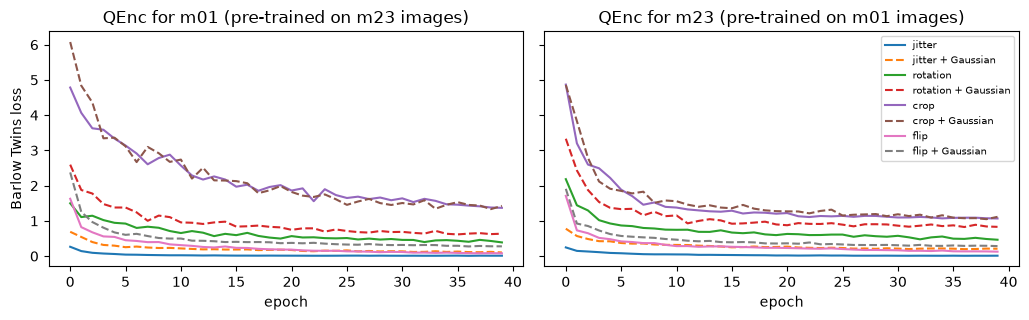

[621 s]
                    first   last  drop_pct
m01 jitter   none   0.265  0.012    95.454
             noise  0.690  0.104    84.967
    rotation none   1.499  0.389    74.050
             noise  2.595  0.636    75.481
    crop     none   4.783  1.370    71.361
             noise  6.074  1.426    76.532
    flip     none   1.627  0.080    95.087
             noise  2.375  0.278    88.302
m23 jitter   none   0.247  0.012    95.065
             noise  0.778  0.210    73.037
    rotation none   2.183  0.465    78.707
             noise  3.330  0.831    75.059
    crop     none   4.867  1.068    78.051
             noise  4.856  1.114    77.053
    flip     none   1.710  0.126    92.615
             noise  1.909  0.284    85.105


In [11]:
def _affine(x, theta):
    return F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), padding_mode="border", align_corners=False)

def aug_jitter(x, g):
    N = len(x); b = 0.6 + 0.8 * torch.rand(N, 1, 1, 1, generator=g); c = 0.6 + 0.8 * torch.rand(N, 1, 1, 1, generator=g)
    m = x.mean((1, 2, 3), keepdim=True)
    return ((x - m) * c + m) * b

def aug_rotation(x, g):
    a = (torch.rand(len(x), generator=g) * 2 - 1) * (math.pi / 6)
    z = torch.zeros_like(a)
    return _affine(x, torch.stack([torch.stack([torch.cos(a), -torch.sin(a), z], 1), torch.stack([torch.sin(a), torch.cos(a), z], 1)], 1))

def aug_crop(x, g):
    N = len(x); s = 0.6 + 0.4 * torch.rand(N, generator=g)
    tx = (torch.rand(N, generator=g) * 2 - 1) * (1 - s); ty = (torch.rand(N, generator=g) * 2 - 1) * (1 - s); z = torch.zeros(N)
    return _affine(x, torch.stack([torch.stack([s, z, tx], 1), torch.stack([z, s, ty], 1)], 1))

def aug_flip(x, g):
    f = torch.rand(len(x), generator=g) < 0.5
    out = x.clone(); out[f] = x[f].flip(-1)
    return out

AUGS = {"jitter": aug_jitter, "rotation": aug_rotation, "crop": aug_crop, "flip": aug_flip}

def augment(x, kind, gauss, g):
    """x: (N,1,16,16) in [0,1]; one transformation `kind` (or a list of kinds: one random pick per image), then Gaussian
    noise ('noise'), a 3x3 blur ('blur') or nothing ('none')."""
    kinds = kind if isinstance(kind, (list, tuple)) else [kind]
    out = x.clone(); pick = torch.randint(len(kinds), (len(x),), generator=g)
    for i, k in enumerate(kinds):
        m = pick == i
        if m.any(): out[m] = AUGS[k](x[m], g)
    if gauss == "noise": out = out + 0.1 * torch.randn(out.shape, generator=g)
    elif gauss == "blur":
        k1 = torch.tensor([1., 2., 1.]); out = F.conv2d(F.pad(out, (1, 1, 1, 1), mode="replicate"), ((k1[:, None] * k1[None]) / 16)[None, None])
    return out.clamp(0, 1)

def barlow_twins_loss(z1, z2, lam):
    """Eq. (4). z1, z2: (N, d) embeddings of the two augmented views."""
    z1 = (z1 - z1.mean(0)) / (z1.std(0) + 1e-6); z2 = (z2 - z2.mean(0)) / (z2.std(0) + 1e-6)
    C = z1.T @ z2 / len(z1)
    return ((1 - torch.diagonal(C)) ** 2).sum() + lam * ((C ** 2).sum() - (torch.diagonal(C) ** 2).sum())

def train_qenc(Xsrc, epochs, bs, kind, gauss, seed, lr=ENC_LR, wd=ENC_WD, lam=ENC_LAMBDA):
    """Pre-train QEnc on UNLABELLED source images Xsrc (N,256) with Barlow Twins. Returns (model, loss per epoch)."""
    model = QNN(N_QUBITS_ENC, N_LAYERS_ENC, seed); opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    g = torch.Generator().manual_seed(int(seed)); hist = []; imgs = Xsrc.reshape(-1, 1, 16, 16).float()
    for ep in range(epochs):
        perm = torch.randperm(len(imgs), generator=g); tot, cnt = 0.0, 0
        for i in range(0, len(imgs) - bs + 1, bs):
            xb = imgs[perm[i:i + bs]]
            v = torch.cat([augment(xb, kind, gauss, g), augment(xb, kind, gauss, g)]).reshape(2 * bs, 256).double()
            z = model(v); loss = barlow_twins_loss(z[:bs], z[bs:], lam)
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item(); cnt += 1
        hist.append(tot / max(cnt, 1))
    return model, hist

# source task whose unlabelled images pre-train the encoder of each target task (paper: "m01 for m23")
SRC_OF = {t: ("m23" if t == "m01" else "m01") if t[0] == "m" else ("f23" if t == "f01" else "f01") for t in TD}
def source_images(src_task, n, seed):
    """n unlabelled 16x16 images of the source task (labels are never used)."""
    Xtr, _ = task_split(src_task, "train")
    return to_16x16(Xtr[np.random.default_rng(seed).choice(len(Xtr), n, replace=False)])
t0 = time.time()
fig6, fig6_models = {}, {}
fig, ax = plt.subplots(1, len(FIG6_TASKS), figsize=(5.2 * len(FIG6_TASKS), 3.3), sharey=True, squeeze=False); ax = ax[0]
for i, tgt in enumerate(FIG6_TASKS):
    Xsrc = source_images(SRC_OF[tgt], ENC_N_SRC, SEED)
    for aug in FIG6_AUGS:
        for gauss in ["none", "noise"]:
            mdl, h = train_qenc(Xsrc, ENC_EPOCHS, ENC_BS, aug, gauss, SEED)
            fig6[(tgt, aug, gauss)] = h; fig6_models[(tgt, aug, gauss)] = mdl
            ax[i].plot(h, ls="-" if gauss == "none" else "--", label=f"{aug}" + (" + Gaussian" if gauss == "noise" else ""))
    ax[i].set_title(f"QEnc for {tgt} (pre-trained on {SRC_OF[tgt]} images)"); ax[i].set_xlabel("epoch")
ax[0].set_ylabel("Barlow Twins loss"); ax[-1].legend(fontsize=7); plt.tight_layout(); plt.show()
print(f"[{time.time() - t0:.0f} s]")
f6 = pd.DataFrame({k: dict(first=v[0], last=v[-1], drop_pct=100 * (1 - v[-1] / v[0])) for k, v in fig6.items()}).T
print(f6.round(3).to_string())

### 6b. The encoders used in the attack

The attack uses the configuration the paper selects, *jitter + Gaussian noise*. One encoder is trained per **source** task:
the m01 images pre-train the encoder for every MNIST task except m01 itself (which uses an m23 encoder); likewise f01 and f23
for Fashion-MNIST. This needs 4 encoders instead of 10 and never lets an encoder see its own target classes. Encoders already
trained for Fig. 6 are reused. Afterwards the encoder embeds the 1000 test images of each task once (the encoder is frozen).

In [12]:
t0 = time.time()
ENC = {}
for t in TASKS:
    src = SRC_OF[t]
    if src in ENC: continue
    reuse = [k for k in fig6_models if SRC_OF[k[0]] == src and k[1] == "jitter" and k[2] == "noise"]
    if reuse:
        ENC[src] = fig6_models[reuse[0]]
    else:
        ENC[src], _ = train_qenc(source_images(src, ENC_N_SRC, SEED), ENC_EPOCHS, ENC_BS, "jitter", "noise", SEED)
def qenc_features(qenc, X16, bs=500):
    with torch.no_grad(): return torch.cat([qenc(X16[i:i + bs]) for i in range(0, len(X16), bs)])
FEAT_TE = {t: qenc_features(ENC[SRC_OF[t]], TD[t]["Xte16"]) for t in TASKS}
def pad16(f):
    """8-dim embedding -> 16 amplitudes (zero padding) for the 4-qubit amplitude-encoded QClassifier. (CHOICE)"""
    return torch.cat([f, torch.zeros(*f.shape[:-1], 16 - f.shape[-1], dtype=f.dtype)], -1)
print("encoders (source task ->):", list(ENC), "| test embeddings:", {t: tuple(v.shape) for t, v in list(FEAT_TE.items())[:2]}, f"[{time.time() - t0:.0f} s]")

encoders (source task ->): ['m23', 'm01', 'f23', 'f01'] | test embeddings: {'m01': (1000, 8), 'm23': (1000, 8)} [114 s]


## 7. The attack and its two baselines, task by task (paper Sec. V-VI, Table III)

For every (task, seed) the notebook now plays the attacker on a fresh simulated day:

1. **Queries.** CopyQNN sends `N_QUERY = 40` images in 5 rounds (200 labels). The two baselines send `N_BIG` images in 5 rounds
   (the paper's QuantumLeak sends 6000 images; we use fewer so that the simulated cloud stays affordable).
2. **Base:** one copy of the victim architecture trained on all labels (every image paired with each round's probability vector).
3. **QuantumLeak:** five copies of the victim architecture, each trained on a bootstrap sample (bagging) of the labels; the
   final label is the majority vote.
4. **CopyQNN:** rank the 40 images by variance, keep the top `RR`, embed them with the frozen QEnc, train the 4-qubit
   QClassifier on (embedding, round probability vector) pairs with mixup (all 5 rounds of every kept image, so 200 pairs at RR = 1).
5. **Extra classical baselines on the same stolen data:** random forest and RBF-SVM trained on the 4x4 pixels (Base-style data,
   `N_BIG` images) and on the QEnc embeddings of the cleaned CopyQNN data (RR = 0.6), using hard round labels.

Accuracy is measured on the 1000 test images against the **true labels** (the paper's metric); we also report the agreement
with the noise-free victim (a fidelity measure) and the accuracy of the stolen labels themselves. Training of all substitutes
is batched across tasks and seeds (Section 2).

In [13]:
t0 = time.time()
RUNS = []
for seed in SEEDS:
    day = DeviceDrift(2000 + seed)                                    # a fresh simulated day per seed (not the calibration day)
    for ti, t in enumerate(TASKS):
        g = np.random.default_rng(seed * 1000 + ti); pool = len(TD[t]["pool_img"])
        i_copy = g.choice(pool, N_QUERY, replace=False); i_big = g.choice(pool, N_BIG, replace=False)
        imgs_c, imgs_b = TD[t]["pool_img"][i_copy], TD[t]["pool_img"][i_big]
        Pc = query_cloud(t, imgs_c, day, NOISE_LEVEL, M_ROUNDS, seed + 11 * ti)            # (m, 40, 2)
        Pb = query_cloud(t, imgs_b, day, NOISE_LEVEL, M_ROUNDS, seed + 11 * ti + 5)         # (m, N_BIG, 2)
        RUNS.append(dict(task=t, seed=seed, Pc=Pc, Pb=Pb, yc=TD[t]["pool_y"][i_copy], yb=TD[t]["pool_y"][i_big],
                         X4c=to_4x4(imgs_c), X4b=to_4x4(imgs_b), imgs_c=imgs_c, Fc=qenc_features(ENC[SRC_OF[t]], to_16x16(imgs_c))))
        print(f"  queried {t} seed {seed}: label accuracy of the stolen labels  CopyQNN data {(Pc.argmax(-1) == RUNS[-1]['yc'][None]).mean():.3f}"
              f" | baseline data {(Pb.argmax(-1) == RUNS[-1]['yb'][None]).mean():.3f}   [{time.time() - t0:.0f} s]", flush=True)
T_QUERY = time.time() - t0
print(f"{len(RUNS)} runs, {sum(r['Pc'].size + r['Pb'].size for r in RUNS) // 2} cloud labels in {T_QUERY:.0f} s")

  queried m01 seed 42: label accuracy of the stolen labels  CopyQNN data 0.880 | baseline data 0.892   [47 s]


  queried m23 seed 42: label accuracy of the stolen labels  CopyQNN data 0.900 | baseline data 0.895   [89 s]


  queried m45 seed 42: label accuracy of the stolen labels  CopyQNN data 0.790 | baseline data 0.813   [127 s]


  queried m67 seed 42: label accuracy of the stolen labels  CopyQNN data 0.915 | baseline data 0.969   [166 s]


  queried m89 seed 42: label accuracy of the stolen labels  CopyQNN data 0.555 | baseline data 0.643   [205 s]


...

  queried f23 seed 44: label accuracy of the stolen labels  CopyQNN data 0.790 | baseline data 0.742   [1056 s]


  queried f45 seed 44: label accuracy of the stolen labels  CopyQNN data 0.895 | baseline data 0.866   [1092 s]


  queried f67 seed 44: label accuracy of the stolen labels  CopyQNN data 1.000 | baseline data 0.999   [1130 s]


  queried f89 seed 44: label accuracy of the stolen labels  CopyQNN data 0.965 | baseline data 0.961   [1171 s]


30 runs, 66000 cloud labels in 1171 s


In [14]:
def rr_pairs(run, rr):
    """CopyQNN training pairs of a run for Remember Ratio rr: embedding of every kept image repeated for each round, with
    that round's probability vector as soft label."""
    keep = remember_ratio_keep(run["Pc"], rr); m = run["Pc"].shape[0]
    return pad16(run["Fc"][keep]).repeat(m, 1), torch.tensor(run["Pc"][:, keep].reshape(-1, 2)), keep

def evaluate(logits, run):
    t = run["task"]; pred = logits.argmax(1); yt = TD[t]["yte"]
    return dict(acc=100 * (pred == yt).double().mean().item(), agree=100 * (pred == VIC[t]["ideal_pred"]).double().mean().item()), pred

ROWS, PREDS = [], {}
def add_rows(method, preds_logits, runs, time_s, extra=None):
    for r, lg in zip(runs, preds_logits):
        e, pred = evaluate(lg, r)
        ROWS.append(dict(task=r["task"], seed=r["seed"], method=method, **e, time_s=time_s / len(runs)))
        PREDS[(r["task"], r["seed"], method)] = pred.numpy()
K = len(RUNS); mR = M_ROUNDS
Xte4_runs = torch.stack([TD[r["task"]]["Xte4"] for r in RUNS])
t0 = time.time()

# ---- Base: one victim-architecture QNN on all stolen labels ----
Xb, Yb, Wb = pad_stack([r["X4b"].repeat(mR, 1) for r in RUNS], [torch.tensor(r["Pb"].reshape(-1, 2)) for r in RUNS])
base = BQNN(K, 4, N_LAYERS_VICTIM, [SEED + i for i in range(K)])
train_batched(base, Xb, Yb, Wb, BIG_EPOCHS, BIG_BS, BIG_LR, 1e-4, SEED)
add_rows(f"Base ({N_BIG} img)", predict_logits(base, Xte4_runs), RUNS, time.time() - t0); print(f"Base trained [{time.time() - t0:.0f} s]", flush=True)

# ---- QuantumLeak: 5 bagged copies + majority vote ----
t1 = time.time(); gq = np.random.default_rng(SEED); members_X, members_Y = [], []
for r in RUNS:
    Xr, Yr = r["X4b"].repeat(mR, 1), torch.tensor(r["Pb"].reshape(-1, 2))
    for _ in range(5):
        bi = torch.tensor(gq.integers(0, len(Xr), len(Xr))); members_X.append(Xr[bi]); members_Y.append(Yr[bi])
Xm, Ym, Wm = pad_stack(members_X, members_Y)
leak = BQNN(5 * K, 4, N_LAYERS_VICTIM, [SEED + 1000 + i for i in range(5 * K)])
train_batched(leak, Xm, Ym, Wm, BIG_EPOCHS, BIG_BS, BIG_LR, 1e-4, SEED + 1)
lg = predict_logits(leak, Xte4_runs.repeat_interleave(5, 0)).argmax(-1).reshape(K, 5, -1)
votes = lg.sum(1)                                                       # number of members voting for class 1
leak_logits = [torch.stack([(5 - v), v], 1).double() for v in votes]    # arg-max = majority vote
add_rows(f"QLeak ({N_BIG} img)", leak_logits, RUNS, time.time() - t1); print(f"QuantumLeak trained [{time.time() - t1:.0f} s]", flush=True)

# ---- Base with the CopyQNN budget (40 images, 200 labels, no cleaning, no transfer learning) ----
t1 = time.time()
Xs40, Ys40, Ws40 = pad_stack([r["X4c"].repeat(mR, 1) for r in RUNS], [torch.tensor(r["Pc"].reshape(-1, 2)) for r in RUNS])
base40 = BQNN(K, 4, N_LAYERS_VICTIM, [SEED + 2000 + i for i in range(K)])
train_batched(base40, Xs40, Ys40, Ws40, 100, 32, 5e-3, 1e-4, SEED + 2)
add_rows("Base (40 img)", predict_logits(base40, Xte4_runs), RUNS, time.time() - t1); print(f"Base-40 trained [{time.time() - t1:.0f} s]", flush=True)

# ---- CopyQNN for every Remember Ratio ----
t1 = time.time(); clf_pairs = []
for rr in RR_GRID:
    for r in RUNS: clf_pairs.append(rr_pairs(r, rr))
Xk, Yk, Wk = pad_stack([p[0] for p in clf_pairs], [p[1] for p in clf_pairs])
clf = BQNN(len(clf_pairs), 4, N_LAYERS_CLF, [SEED + 3000 + i for i in range(len(clf_pairs))])
train_batched(clf, Xk, Yk, Wk, CLF_EPOCHS, len(Xk[0]), CLF_LR, CLF_WD, SEED + 3, mixup_alpha=MIXUP_ALPHA)
Xte_feat = torch.stack([pad16(FEAT_TE[r["task"]]) for r in RUNS] * len(RR_GRID))
lg_all = predict_logits(clf, Xte_feat)
t_clf = time.time() - t1
for i, rr in enumerate(RR_GRID):
    add_rows(f"CopyQNN RR={rr}", lg_all[i * K:(i + 1) * K], RUNS, t_clf / len(RR_GRID))
print(f"CopyQNN classifiers trained [{t_clf:.0f} s]", flush=True)

# ---- classical substitutes on the same stolen data ----
t1 = time.time(); crow = []
for r in RUNS:
    t = r["task"]; Xte4, Fte = TD[t]["Xte4"].numpy(), FEAT_TE[t].numpy(); yt = TD[t]["yte"].numpy()
    Xbig = np.tile(r["X4b"].numpy(), (mR, 1)); ybig = r["Pb"].argmax(-1).reshape(-1)                  # hard round labels
    keep = remember_ratio_keep(r["Pc"], 0.6)
    Xcl, ycl = np.tile(r["Fc"][keep].numpy(), (mR, 1)), r["Pc"][:, keep].argmax(-1).reshape(-1)
    for name, mdl, Xa, ya, Xt in [(f"RF 4x4 ({N_BIG} img)", RandomForestClassifier(200, random_state=SEED), Xbig, ybig, Xte4),
                                  (f"SVC-rbf 4x4 ({N_BIG} img)", SVC(kernel="rbf"), Xbig, ybig, Xte4),
                                  ("RF QEnc (RR=0.6)", RandomForestClassifier(200, random_state=SEED), Xcl, ycl, Fte),
                                  ("SVC-rbf QEnc (RR=0.6)", SVC(kernel="rbf"), Xcl, ycl, Fte)]:
        if len(np.unique(ya)) < 2:
            pred = np.full(len(yt), ya[0])
        else:
            pred = mdl.fit(Xa, ya).predict(Xt)
        ROWS.append(dict(task=t, seed=r["seed"], method=name, acc=100 * (pred == yt).mean(),
                         agree=100 * (pred == VIC[t]["ideal_pred"].numpy()).mean(), time_s=np.nan))
print(f"classical substitutes [{time.time() - t1:.0f} s]")
RES = pd.DataFrame(ROWS)
for r in RUNS:
    ROWS.append(dict(task=r["task"], seed=r["seed"], method="victim ideal (reference)", acc=100 * VIC[r["task"]]["ideal_acc"], agree=100.0, time_s=np.nan))
RES = pd.DataFrame(ROWS)
print("all methods done, total", f"{time.time() - t0:.0f} s")

Base trained [41 s]


QuantumLeak trained [138 s]


Base-40 trained [20 s]


CopyQNN classifiers trained [176 s]


classical substitutes [77 s]
all methods done, total 453 s


### 7b. Table III re-computed: accuracy of the substitute (%)

Mean over seeds (and, for the last columns, standard deviation over seeds and tasks). The second table is the paper's Table III
for the same tasks. The paper's columns show a single run on the real device.

=== this notebook (mean over seeds, test accuracy %) ===


method  victim ideal (reference)  Base (400 img)  QLeak (400 img)  Base (40 img)  CopyQNN RR=0.1  CopyQNN RR=0.2  CopyQNN RR=0.3  CopyQNN RR=0.4  CopyQNN RR=0.5  CopyQNN RR=0.6  CopyQNN RR=0.7  CopyQNN RR=0.8  CopyQNN RR=0.9  CopyQNN RR=1.0
task                                                                                                                                                                                                                                            
m01                         92.7            84.3             83.8           81.9            72.9            74.7            80.4            89.7            87.4            86.9            93.3            87.9            87.8            85.1
m23                         87.6            83.8             85.8           83.0            57.7            70.1            73.5            71.2            73.8            78.8            74.6            79.6            79.9            81.4
m45                         94.4   

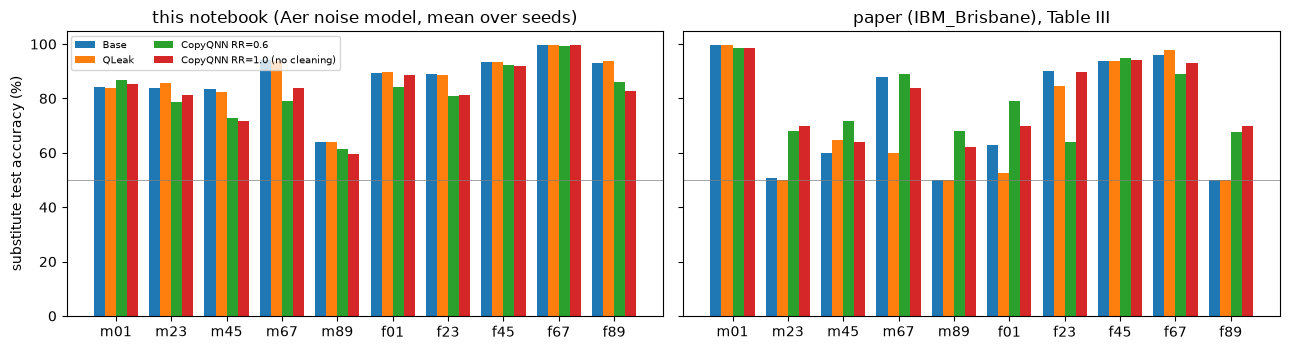

In [15]:
PAPER_T3 = pd.DataFrame({
 "Base":  [99.6, 50.8, 60.0, 87.9, 50.0, 63.0, 90.0, 93.6, 96.1, 50.0],
 "QLeak": [99.6, 50.0, 64.7, 59.9, 50.0, 52.4, 84.5, 93.6, 97.9, 50.0],
 **{f"RR={r}": v for r, v in zip([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0], [
    [91.2, 83.9, 42.7, 75.9, 43.3, 46.1, 60.6, 50.0, 50.9, 60.2], [81.4, 81.3, 47.4, 79.5, 58.7, 49.5, 55.9, 50.0, 49.3, 63.0],
    [72.8, 76.8, 50.1, 73.8, 52.9, 82.3, 51.9, 81.3, 91.1, 65.9], [92.5, 63.3, 65.4, 78.4, 53.1, 77.5, 59.9, 81.4, 91.7, 70.9],
    [97.6, 62.2, 48.6, 84.3, 59.7, 88.7, 71.4, 93.9, 88.5, 70.6], [98.7, 67.9, 71.8, 88.9, 68.1, 79.2, 63.9, 94.8, 89.1, 67.5],
    [98.0, 64.9, 69.9, 87.5, 58.4, 74.4, 80.0, 94.5, 90.1, 63.1], [98.4, 59.8, 67.4, 88.3, 64.2, 74.1, 79.5, 95.1, 94.0, 63.1],
    [98.4, 63.5, 62.2, 88.4, 64.8, 68.4, 83.5, 95.0, 92.8, 65.9], [98.4, 70.0, 64.1, 83.9, 62.1, 69.9, 89.8, 94.1, 92.9, 69.9]])}},
 index=["m01", "m23", "m45", "m67", "m89", "f01", "f23", "f45", "f67", "f89"])

def method_names():
    m = [f"Base ({N_BIG} img)", f"QLeak ({N_BIG} img)", "Base (40 img)"] + [f"CopyQNN RR={r}" for r in RR_GRID]
    return m
mt = RES[RES.method.isin(method_names() + ["victim ideal (reference)"])].pivot_table(index="task", columns="method", values="acc", aggfunc="mean").reindex(TASKS)
mt = mt[["victim ideal (reference)"] + method_names()]
mt.loc["mean"] = mt.mean()
print("=== this notebook (mean over seeds, test accuracy %) ===")
print(mt.round(1).to_string())
print("\n=== paper, Table III (same tasks) ===")
pt = PAPER_T3.loc[TASKS].copy(); pt.loc["mean"] = pt.mean()
print(pt[["Base", "QLeak"] + [f"RR={r}" for r in RR_GRID]].round(1).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
xs = np.arange(len(TASKS)); w = 0.2
for j, (lab, col_here, col_paper) in enumerate([("Base", f"Base ({N_BIG} img)", "Base"), ("QLeak", f"QLeak ({N_BIG} img)", "QLeak"),
                                                ("CopyQNN RR=0.6", "CopyQNN RR=0.6", "RR=0.6"), ("CopyQNN RR=1.0 (no cleaning)", "CopyQNN RR=1.0", "RR=1.0")]):
    ax[0].bar(xs + (j - 1.5) * w, mt.loc[TASKS, col_here], w, label=lab); ax[1].bar(xs + (j - 1.5) * w, pt.loc[TASKS, col_paper], w, label=lab)
for a, ttl in zip(ax, ["this notebook (Aer noise model, mean over seeds)", "paper (IBM_Brisbane), Table III"]):
    a.set_xticks(xs); a.set_xticklabels(TASKS); a.set_title(ttl); a.axhline(50, color="grey", lw=0.5)
ax[0].set_ylabel("substitute test accuracy (%)"); ax[0].legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

Classical substitutes (RF, SVC) trained on the same stolen data: test accuracy %
method  RF 4x4 (400 img)  RF QEnc (RR=0.6)  SVC-rbf 4x4 (400 img)  SVC-rbf QEnc (RR=0.6)
task                                                                                    
m01                 85.3              86.8                   86.2                   88.6
m23                 84.4              70.7                   85.0                   78.7
m45                 82.7              81.0                   84.1                   85.5
m67                 96.1              82.2                   96.4                   83.1
m89                 59.4              51.7                   60.2                   50.5
f01                 91.9              90.3                   93.1                   92.2
f23                 89.1              80.8                   91.2                   82.2
f45                 94.5              91.8                   94.8                   96.2
f67                 99.8     

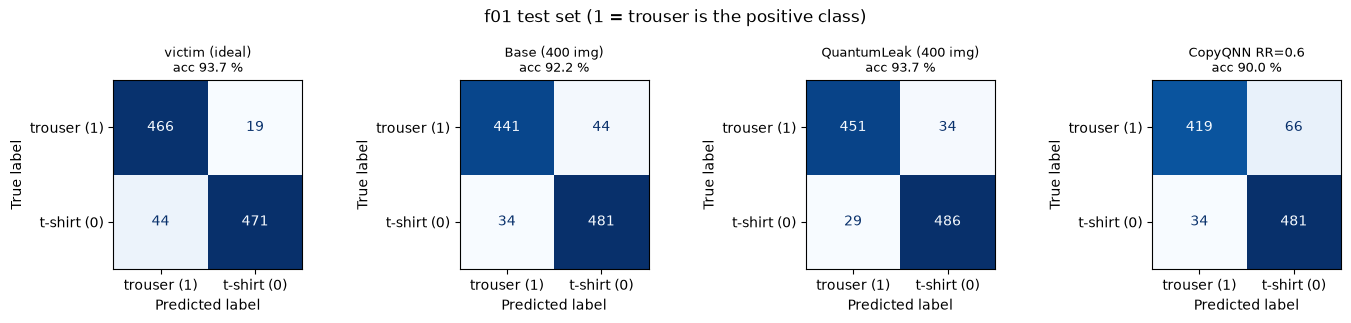

In [16]:
# Where the substitutes differ from the victim: agreement with the noise-free victim, stolen-label quality, extra classical substitutes
ag = RES.pivot_table(index="task", columns="method", values="agree", aggfunc="mean").reindex(TASKS)
extra = RES[~RES.method.isin(method_names() + ["victim ideal (reference)"])].pivot_table(index="task", columns="method", values="acc", aggfunc="mean").reindex(TASKS)
extra.loc["mean"] = extra.mean()
print("Classical substitutes (RF, SVC) trained on the same stolen data: test accuracy %")
print(extra.round(1).to_string())
print("\nAgreement (%) of the substitute with the noise-free victim on the test images (mean over seeds), selected methods:")
sel = ag[[c for c in [f"Base ({N_BIG} img)", f"QLeak ({N_BIG} img)", "Base (40 img)", "CopyQNN RR=0.6", "CopyQNN RR=1.0"] if c in ag.columns]]
sel.loc["mean"] = sel.mean(); print(sel.round(1).to_string())
lab_q = pd.DataFrame({"stolen-label accuracy CopyQNN data (%)": [100 * np.mean([(r["Pc"].argmax(-1) == r["yc"][None]).mean() for r in RUNS if r["task"] == t]) for t in TASKS],
                      "stolen-label accuracy baseline data (%)": [100 * np.mean([(r["Pb"].argmax(-1) == r["yb"][None]).mean() for r in RUNS if r["task"] == t]) for t in TASKS]}, index=TASKS)
print("\nAccuracy of the stolen labels (all rounds pooled, before any cleaning):"); print(lab_q.round(1).to_string())

# confusion matrices on f01 (attack = positive class), first seed: victim, Base, QuantumLeak, CopyQNN RR=0.6
t_cm, s_cm = "f01", SEEDS[0]
fig, ax = plt.subplots(1, 4, figsize=(14, 3.2))
yt = TD[t_cm]["yte"].numpy()
for a, (name, pred) in zip(ax, [("victim (ideal)", VIC[t_cm]["ideal_pred"].numpy()), (f"Base ({N_BIG} img)", PREDS[(t_cm, s_cm, f"Base ({N_BIG} img)")]),
                                (f"QuantumLeak ({N_BIG} img)", PREDS[(t_cm, s_cm, f"QLeak ({N_BIG} img)")]), ("CopyQNN RR=0.6", PREDS[(t_cm, s_cm, "CopyQNN RR=0.6")])]):
    ConfusionMatrixDisplay(confusion_matrix(yt, pred, labels=[1, 0]), display_labels=[FASHION_NAMES[1] + " (1)", FASHION_NAMES[0] + " (0)"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"{name}\nacc {100 * (pred == yt).mean():.1f} %", fontsize=9)
plt.suptitle("f01 test set (1 = trouser is the positive class)"); plt.tight_layout(); plt.show()

## 8. More query rounds help (paper Fig. 7)

The paper varies the number of query rounds `m` from 2 to 40 with the same 40 images and RR = 0.6; the accuracy of the
substitute rises from 72.34 % (2 rounds) to 87.40 % (40 rounds) with diminishing returns. The paper does not say which task(s)
the curve belongs to; we average over the tasks listed in `SWEEP_TASKS` (all ten in the full run). More rounds mean more labels
per image, more of the day covered, and more suspicious traffic. Rounds are spread evenly over 24 h (`h_k = 24 k / m`).

  swept seed 42  [591 s]


    here (mean over tasks/seeds)  paper (Fig. 7)
2                          82.17           72.34
4                          81.99           74.60
10                         77.40           83.77
20                         78.48           84.99
40                         78.58           87.40


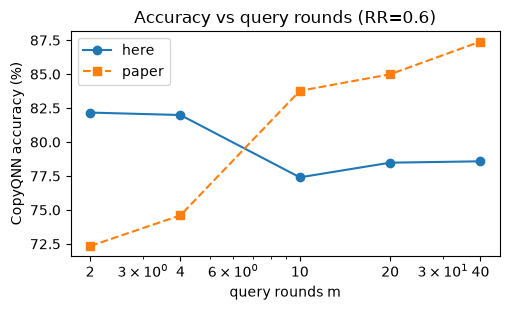

[672 s]


In [17]:
t0 = time.time()
sweep_runs = []
for seed in SWEEP_SEEDS:
    day = DeviceDrift(3000 + seed)
    for ti, t in enumerate(SWEEP_TASKS):
        g = np.random.default_rng(seed * 1000 + 77 + ti); idx = g.choice(len(TD[t]["pool_img"]), N_QUERY, replace=False)
        imgs = TD[t]["pool_img"][idx]; Fc = qenc_features(ENC[SRC_OF[t]], to_16x16(imgs))
        for m in SWEEP_ROUNDS:
            P = query_cloud(t, imgs, day, NOISE_LEVEL, m, seed + 13 * ti + m)
            sweep_runs.append(dict(task=t, seed=seed, m=m, Pc=P, Fc=Fc))
    print(f"  swept seed {seed}  [{time.time() - t0:.0f} s]", flush=True)
pairs = []
for r in sweep_runs:
    keep = remember_ratio_keep(r["Pc"], 0.6)
    pairs.append((pad16(r["Fc"][keep]).repeat(r["m"], 1), torch.tensor(r["Pc"][:, keep].reshape(-1, 2))))
Xk, Yk, Wk = pad_stack([p[0] for p in pairs], [p[1] for p in pairs])
clf_s = BQNN(len(pairs), 4, N_LAYERS_CLF, [SEED + 5000 + i for i in range(len(pairs))])
train_batched(clf_s, Xk, Yk, Wk, CLF_EPOCHS, Xk.shape[1], CLF_LR, CLF_WD, SEED + 5, mixup_alpha=MIXUP_ALPHA)
lg_s = predict_logits(clf_s, torch.stack([pad16(FEAT_TE[r["task"]]) for r in sweep_runs]))
SW = pd.DataFrame([dict(task=r["task"], seed=r["seed"], m=r["m"], acc=100 * (lg_s[i].argmax(1) == TD[r["task"]]["yte"]).double().mean().item())
                   for i, r in enumerate(sweep_runs)])
sw_mean = SW.groupby("m").acc.mean().reindex(SWEEP_ROUNDS)
PAPER_FIG7 = {2: 72.34, 4: 74.60, 10: 83.77, 20: 84.99, 40: 87.40}
print(pd.DataFrame({"here (mean over tasks/seeds)": sw_mean, "paper (Fig. 7)": pd.Series(PAPER_FIG7).reindex(SWEEP_ROUNDS)}).round(2).to_string())
plt.figure(figsize=(5.2, 3.2)); plt.plot(SWEEP_ROUNDS, sw_mean.values, "o-", label="here")
plt.plot(SWEEP_ROUNDS, [PAPER_FIG7[m] for m in SWEEP_ROUNDS], "s--", label="paper")
plt.xscale("log"); plt.xticks(SWEEP_ROUNDS, SWEEP_ROUNDS); plt.xlabel("query rounds m"); plt.ylabel("CopyQNN accuracy (%)"); plt.legend(); plt.title("Accuracy vs query rounds (RR=0.6)")
plt.tight_layout(); plt.show(); print(f"[{time.time() - t0:.0f} s]")

## 9. Design overhead (paper Table II)

Table II compares the cost of CopyQNN and QuantumLeak: the number of queried images, rounds and labels, and the number of
trainable single-qubit-gate (1QG) and two-qubit-gate (2QG) parameters. The counts below are taken from the circuits that this
notebook actually builds (`QNN`, `BQNN`), so they check that the architecture we implemented is the one the paper counts.

In [18]:
enc_p = QNN(N_QUBITS_ENC, N_LAYERS_ENC, 0).params.numel()                      # 4 numbers per qubit and layer: 3 rotations + 1 CRX
clf_p = BQNN(1, 4, N_LAYERS_CLF, [0]).params.numel()
leak_p = 5 * BQNN(1, 4, N_LAYERS_VICTIM, [0]).params.numel()
cnt = lambda q, L: (3 * q * L, q * L)
tab2 = pd.DataFrame({
    "QuantumLeak (paper)": {"images": 6000, "rounds": 3, "labels": 6000 * 3, "1QG params": 120, "2QG params": 40},
    "CopyQNN (paper)":     {"images": 40, "rounds": 5, "labels": 200, "1QG params": 144, "2QG params": 48},
    "QuantumLeak (here, paper scale)": {"images": 6000, "rounds": 3, "labels": 6000 * 3, "1QG params": 5 * cnt(4, 2)[0], "2QG params": 5 * cnt(4, 2)[1]},
    "CopyQNN (here)":      {"images": N_QUERY, "rounds": M_ROUNDS, "labels": N_QUERY * M_ROUNDS,
                            "1QG params": cnt(N_QUBITS_ENC, N_LAYERS_ENC)[0] + cnt(4, N_LAYERS_CLF)[0], "2QG params": cnt(N_QUBITS_ENC, N_LAYERS_ENC)[1] + cnt(4, N_LAYERS_CLF)[1]},
}).T
print(tab2.to_string())
assert enc_p + clf_p == tab2.loc["CopyQNN (here)", "1QG params"] + tab2.loc["CopyQNN (here)", "2QG params"]
assert leak_p == tab2.loc["QuantumLeak (here, paper scale)", "1QG params"] + tab2.loc["QuantumLeak (here, paper scale)", "2QG params"]
q_ratio = tab2.loc["QuantumLeak (here, paper scale)", "labels"] / tab2.loc["CopyQNN (here)", "labels"]
hw = (tab2.loc["CopyQNN (here)", ["1QG params", "2QG params"]].sum() / tab2.loc["QuantumLeak (here, paper scale)", ["1QG params", "2QG params"]].sum() - 1) * 100
print(f"query reduction {q_ratio:.0f}x | trainable-gate overhead {hw:+.0f} %   (paper: 90x fewer queries, +20 % hardware)")

                                 images  rounds  labels  1QG params  2QG params
QuantumLeak (paper)                6000       3   18000         120          40
CopyQNN (paper)                      40       5     200         144          48
QuantumLeak (here, paper scale)    6000       3   18000         120          40
CopyQNN (here)                       40       5     200         144          48
query reduction 90x | trainable-gate overhead +20 %   (paper: 90x fewer queries, +20 % hardware)


## 10. Optional: the same query on real IBM hardware

The paper ran on IBM_Brisbane. If you have an IBM Quantum account you can put its API token into `IBM_TOKEN` in the
configuration cell and re-run this cell: it sends 50 f01 test images to the least busy real backend with the f01 victim's
circuit and prints the accuracy next to the ideal one. With an empty token (the default) the cell is skipped. This cell was
**not executed** while preparing the notebook (no account, no budget); everything else in the notebook is independent of it.

In [19]:
if not IBM_TOKEN:
    print("IBM_TOKEN is empty -> real-hardware cell skipped (the simulated cloud above is used everywhere).")
else:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_TOKEN)
    backend = service.least_busy(operational=True, simulator=False)
    amps = (TD["f01"]["Xte4"][:50] / TD["f01"]["Xte4"][:50].norm(dim=1, keepdim=True)).numpy().astype(complex)
    circs = []
    for v in amps:
        qc = QuantumCircuit(4, 4); qc.initialize(v, range(4)); qc.compose(var_circuit(VIC["f01"]["params"], 4), inplace=True); qc.measure(range(4), range(4)); circs.append(qc)
    isa = transpile(circs, backend=backend, optimization_level=1)
    res = SamplerV2(mode=backend).run(isa, shots=SHOTS).result()
    sgn = np.array([[1 - 2 * ((k >> q) & 1) for q in range(4)] for k in range(16)])
    raw = np.array([sum(c * sgn[int(k, 2)] for k, c in res[i].data.c.get_counts().items()) / SHOTS for i in range(len(circs))])
    acc = (head(torch.tensor(raw)).argmax(1).numpy() == TD["f01"]["yte"][:50].numpy()).mean()
    print(f"{backend.name}: f01 victim accuracy on 50 test images {100 * acc:.1f} % (ideal {100 * VIC['f01']['ideal_acc']:.1f} %)")

IBM_TOKEN is empty -> real-hardware cell skipped (the simulated cloud above is used everywhere).


## 11. Side by side with the paper: a verdict for every claim

Rule (from the project's validation requirements): an accuracy-like number is **reproduced** when it is within 2 points of
the paper's value, otherwise **not reached** (lower) or **exceeded** (higher). Qualitative claims get a verdict from an explicit
criterion that is printed with them. Claims that need the real device or numbers the paper does not give are marked
**cannot be checked**. Remember that our "hardware" is a noise model with one fitted scale, so the per-task cells of Table III
are expected to differ from the real device.

In [20]:
def verdict(paper, here, tol=2.0):
    d = here - paper
    return "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else "not reached")

rows = []
def claim(cid, text, paper, here, verd): rows.append(dict(claim=cid, description=text, paper=paper, here=here, verdict=verd))

# C1 ------------------------------------------------------------------------------------------------------------
cal_row = cal_df.loc[NOISE_LEVEL]
claim("C1a", "f01 victim, ideal accuracy (%)", 97.8, round(100 * VIC["f01"]["ideal_acc"], 1), verdict(97.8, 100 * VIC["f01"]["ideal_acc"]))
claim("C1b", "f01 victim on the 'device', mean accuracy over 5 times (%)", 79.7, round(cal_row["mean acc (%)"], 1), "calibrated by construction")
claim("C1c", "f01 victim, spread max-min over the day (points, mean of simulated days)", 14.0, round(cal_row["within-day spread max-min"], 1), verdict(14.0, cal_row["within-day spread max-min"], 4.0) + " (tol 4)")
# C2 ------------------------------------------------------------------------------------------------------------
m_ = RES[(RES.task == "f01")].groupby("method").acc.mean()
claim("C2a", f"f01 Base accuracy (%) [{N_BIG} images here, 6000 in paper]", 63.0, round(m_[f"Base ({N_BIG} img)"], 1), verdict(63.0, m_[f"Base ({N_BIG} img)"]))
claim("C2b", f"f01 QuantumLeak accuracy (%) [{N_BIG} images here]", 52.4, round(m_[f"QLeak ({N_BIG} img)"], 1), verdict(52.4, m_[f"QLeak ({N_BIG} img)"]))
claim("C2c", "f01: QuantumLeak is worse than Base (both far below the ideal victim)", "yes (52.4 < 63.0)", f"{m_[f'QLeak ({N_BIG} img)']:.1f} vs {m_[f'Base ({N_BIG} img)']:.1f}",
      "reproduced" if m_[f"QLeak ({N_BIG} img)"] < m_[f"Base ({N_BIG} img)"] else "not reached")
# C3 ------------------------------------------------------------------------------------------------------------
for t in FIG4_TASKS:
    if t in fig4:
        p1, p6 = PAPER_FIG4[t]; h1, h6 = 100 * fig4[t]["clean_rr1"], 100 * fig4[t]["clean_rr06"]
        claim(f"C3 {t}", "clean-label share: gain from RR=1 to RR=0.6 (points)", f"{p6 - p1:+.1f} ({p1} -> {p6})", f"{h6 - h1:+.1f} ({h1:.1f} -> {h6:.1f})",
              verdict(p6 - p1, h6 - h1) if h6 > h1 else "not reached (no gain)")
vc = [(fig4[t]["var_correct"], fig4[t]["var_wrong"]) for t in fig4 if not np.isnan(fig4[t]["var_wrong"])]
claim("C3 var", "wrongly labelled images have lower variance than correct ones (tasks where true)", "all tasks (Fig. 4)", f"{sum(w < c for c, w in vc)} of {len(vc)}",
      "reproduced" if vc and all(w < c for c, w in vc) else ("partially" if any(w < c for c, w in vc) else "not reached"))
# C4 ------------------------------------------------------------------------------------------------------------
last_first = [v[-1] / v[0] for v in fig6.values()]
claim("C4a", "contrastive loss converges for every augmentation (final < initial loss)", "yes", f"{sum(x < 1 for x in last_first)} of {len(last_first)} curves", "reproduced" if all(x < 1 for x in last_first) else "not reached")
g_no = np.mean([v[-1] for k, v in fig6.items() if k[2] == "none"]); g_yes = np.mean([v[-1] for k, v in fig6.items() if k[2] == "noise"])
claim("C4b", "Gaussian noise raises the final loss slightly", "yes", f"{g_no:.2f} -> {g_yes:.2f}", "reproduced" if g_yes > g_no else "not reached")
fin = {a: np.mean([v[-1] for k, v in fig6.items() if k[1] == a]) for a in FIG6_AUGS}
claim("C4c", "no big differences between augmentations (the paper judges by feature separability and gives no numbers; Barlow Twins losses of different augmentations are not comparable)", "yes (no numbers)",
      "final loss " + ", ".join(f"{a} {v:.2f}" for a, v in fin.items()), "cannot be checked")# C5 ------------------------------------------------------------------------------------------------------------
for m in SWEEP_ROUNDS:
    claim(f"C5 m={m}", "CopyQNN accuracy with m query rounds (%) [paper: unspecified task / average]", PAPER_FIG7[m], round(sw_mean[m], 1), verdict(PAPER_FIG7[m], sw_mean[m]))
claim("C5 trend", "accuracy rises with the number of rounds (largest m better than smallest m)", "yes (+15 points from 2 to 40)", f"{sw_mean.iloc[-1] - sw_mean.iloc[0]:+.1f} points ({SWEEP_ROUNDS[0]} -> {SWEEP_ROUNDS[-1]})",
      "reproduced" if sw_mean.iloc[-1] > sw_mean.iloc[0] + 2 else "not reached")
# C6 / C7 -------------------------------------------------------------------------------------------------------
piv = RES.pivot_table(index="task", columns="method", values="acc", aggfunc="mean").reindex(TASKS)
cells = []
for t in TASKS:
    for lab, hcol, pcol in [("Base", f"Base ({N_BIG} img)", "Base"), ("QLeak", f"QLeak ({N_BIG} img)", "QLeak"), ("RR=0.6", "CopyQNN RR=0.6", "RR=0.6"), ("RR=1.0", "CopyQNN RR=1.0", "RR=1.0")]:
        cells.append(dict(task=t, column=lab, paper=PAPER_T3.loc[t, pcol], here=round(piv.loc[t, hcol], 1), verdict=verdict(PAPER_T3.loc[t, pcol], piv.loc[t, hcol])))
CELLS = pd.DataFrame(cells)
n_rep = (CELLS.verdict == "reproduced").sum()
claim("C6", f"Table III cells (Base, QLeak, RR=0.6, RR=1.0 for {len(TASKS)} tasks) within 2 points", f"{len(CELLS)} cells", f"{n_rep} of {len(CELLS)} cells reproduced",
      "reproduced" if n_rep >= 0.8 * len(CELLS) else ("partially" if n_rep >= 0.25 * len(CELLS) else "not reached"))
imp_here = piv["CopyQNN RR=0.6"] - piv[f"QLeak ({N_BIG} img)"]; imp_paper = PAPER_T3.loc[TASKS, "RR=0.6"] - PAPER_T3.loc[TASKS, "QLeak"]
claim("C7a", f"mean improvement of CopyQNN (RR=0.6) over QuantumLeak (points, {len(TASKS)} tasks)", round(imp_paper.mean(), 2), round(imp_here.mean(), 2), verdict(imp_paper.mean(), imp_here.mean()))
if "m67" in TASKS:
    claim("C7b", "improvement on m67 (points)", 29.0, round(imp_here["m67"], 1), verdict(29.0, imp_here["m67"]))
rr_means = piv[[f"CopyQNN RR={r}" for r in RR_GRID]].mean()
pr_means = PAPER_T3.loc[TASKS, [f"RR={r}" for r in RR_GRID]].mean()
claim("C7c", "best Remember Ratio on average", f"RR={pr_means.idxmax().split('=')[1]} (paper picks 0.6)", f"RR={rr_means.idxmax().split('RR=')[1]}", "reproduced" if abs(float(rr_means.idxmax().split('RR=')[1]) - 0.6) < 0.15 else "not reached")
worse_here = int((piv["CopyQNN RR=1.0"] < piv[f"QLeak ({N_BIG} img)"]).sum()); worse_paper = int((PAPER_T3.loc[TASKS, "RR=1.0"] < PAPER_T3.loc[TASKS, "QLeak"]).sum())
claim("C7d", "tasks where RR=1 (no cleaning) is worse than QuantumLeak", f"{worse_paper} of {len(TASKS)}", f"{worse_here} of {len(TASKS)}", "reproduced" if abs(worse_here - worse_paper) <= 1 else "not reached")
claim("C7e", "cleaning helps: mean accuracy RR=0.6 above RR=1.0 (points)", round(PAPER_T3.loc[TASKS, "RR=0.6"].mean() - PAPER_T3.loc[TASKS, "RR=1.0"].mean(), 2), round((piv["CopyQNN RR=0.6"] - piv["CopyQNN RR=1.0"]).mean(), 2),
      verdict(PAPER_T3.loc[TASKS, "RR=0.6"].mean() - PAPER_T3.loc[TASKS, "RR=1.0"].mean(), (piv["CopyQNN RR=0.6"] - piv["CopyQNN RR=1.0"]).mean()))
# C8 ------------------------------------------------------------------------------------------------------------
claim("C8a", "query reduction CopyQNN vs QuantumLeak (x)", 90, round(q_ratio, 0), verdict(90, q_ratio, 1))
claim("C8b", "trainable-gate parameters 1QG / 2QG (CopyQNN)", "144 / 48", f"{int(tab2.loc['CopyQNN (here)', '1QG params'])} / {int(tab2.loc['CopyQNN (here)', '2QG params'])}", "reproduced" if (tab2.loc['CopyQNN (here)', '1QG params'], tab2.loc['CopyQNN (here)', '2QG params']) == (144, 48) else "not reached")
claim("C8c", "trainable-gate parameters 1QG / 2QG (QuantumLeak)", "120 / 40", f"{int(tab2.loc['QuantumLeak (here, paper scale)', '1QG params'])} / {int(tab2.loc['QuantumLeak (here, paper scale)', '2QG params'])}", "reproduced")
claim("C8d", "hardware overhead of CopyQNN over QuantumLeak (%)", 20, round(hw, 0), verdict(20, hw, 1))
claim("-", "results on the real IBM_Brisbane device", "Table III, Fig. 2, Fig. 7", "simulated noise only", "cannot be checked")
VERD = pd.DataFrame(rows)
print(VERD.to_string(index=False, max_colwidth=78))
print("\nPer-cell comparison for Table III (Base, QuantumLeak, RR=0.6, RR=1.0):"); print(CELLS.pivot(index="task", columns="column", values=["paper", "here"]).reindex(TASKS).to_string())
print("\nverdict counts:", VERD.verdict.str.split(" ").str[0].value_counts().to_dict())
print(f"\nTotal notebook run time: {(time.time() - T_START) / 60:.1f} min (FAST_MODE={FAST_MODE})")

   claim                                                                    description                         paper                                                        here                    verdict
     C1a                                                 f01 victim, ideal accuracy (%)                          97.8                                                        93.7                not reached
     C1b                     f01 victim on the 'device', mean accuracy over 5 times (%)                          79.7                                                        79.8 calibrated by construction
     C1c       f01 victim, spread max-min over the day (points, mean of simulated days)                          14.0                                                        10.7         reproduced (tol 4)
     C2a                         f01 Base accuracy (%) [400 images here, 6000 in paper]                          63.0                                                        89.5   



Per-cell comparison for Table III (Base, QuantumLeak, RR=0.6, RR=1.0):
       paper                      here                    
column  Base QLeak RR=0.6 RR=1.0  Base QLeak RR=0.6 RR=1.0
task                                                      
m01     99.6  99.6   98.7   98.4  84.3  83.8   86.9   85.1
m23     50.8  50.0   67.9   70.0  83.8  85.8   78.8   81.4
m45     60.0  64.7   71.8   64.1  83.4  82.5   72.6   71.7
m67     87.9  59.9   88.9   83.9  94.1  93.7   79.0   83.8
m89     50.0  50.0   68.1   62.1  64.0  64.1   61.4   59.5
f01     63.0  52.4   79.2   69.9  89.5  89.6   84.4   88.5
f23     90.0  84.5   63.9   89.8  89.0  88.5   80.9   81.1
f45     93.6  93.6   94.8   94.1  93.5  93.4   92.3   92.1
f67     96.1  97.9   89.1   92.9  99.6  99.7   99.4   99.5
f89     50.0  50.0   67.5   69.9  93.1  93.6   86.0   82.8

verdict counts: {'not': 13, 'reproduced': 11, 'exceeded': 4, 'cannot': 2, 'calibrated': 1}

Total notebook run time: 58.2 min (FAST_MODE=False)


## 12. Reading the paper critically

*What the experiment supports.* The attack pipeline is easy to implement from the paper, and the pieces behave as described:
the variance of an image's answers over several query rounds is a usable quality score (Section 5), the Barlow Twins loss of
a quantum encoder decreases for every augmentation (Section 6), and the design-overhead arithmetic of Table II is exact
(Section 9). Cleaning with a Remember Ratio and querying more rounds are cheap ideas that can be tested without a quantum computer.

*What this simulation could not confirm, and why that matters.*

1. **The size of the effect depends entirely on how bad the cloud's labels are.** In the paper the naive Base and the
   QuantumLeak ensemble collapse (50-64 % on many tasks, Table III), because the real device returns wrong labels for a large
   share of the queries (clean share 63-87 %, Fig. 4). In our noise model, calibrated on one number (the mean accuracy of the
   f01 victim over a day), the stolen labels are considerably cleaner, so the baselines lose much less than in the paper and
   there is less for the cleaning and the transfer learning to repair. A different, equally plausible noise model (more
   coherent error, crosstalk, leakage) would change the table. The paper's headline "+8.73 points over QuantumLeak" is therefore
   a statement about IBM_Brisbane on one day, not about quantum noise in general.
2. **One run per cell.** Table III shows one number per task and column; with 40 images, 1000 test images and a noise level that
   changes between days, one cell can move by several points from run to run. Our seeds (different simulated days, query sets,
   initialisations) show the spread; the paper gives no error bars, so differences of a few points between columns, and the
   claim "RR = 0.6 is best", cannot be established from the paper alone.
3. **No fair budget for the baselines.** CopyQNN uses 200 labels and the baselines 18000 (a 90x difference that the paper
   advertises). The more informative comparison is at *equal* labels: the notebook adds "Base (40 img)", the same victim
   architecture trained on exactly the 200 labels CopyQNN sees, without cleaning or transfer. Whether CopyQNN beats it
   depends on how good the pre-trained encoder is, which in turn depends on training budgets that the paper does not give
   (size of the source set, number of steps).
4. **Choices hidden in the details.** The paper does not say how the 8-dim embedding enters the 4-qubit classifier, which
   task Fig. 7 belongs to, how mixup is applied, what lambda is, where the 40 query images come from, and how its 97.8 %
   ideal accuracy for a 4-qubit amplitude-encoded victim is reached (a 4x4 downsampled image limits even classical models to
   about 93 % on f01). Fig. 4 reports different numbers of samples per task (172, 362, 262, 323) although Table II says 40
   images, which we could not reconcile.
5. **Threat model.** A provider who only wants to stop extraction could add noise or rate-limit queries; the stealth argument
   (fewer queries) assumes the provider watches query counts, but five rounds of the same 40 images at fixed times of the day
   is itself an unusual pattern that a monitor could flag.
6. **Why variance would indicate noise-induced errors.** The paper's argument is empirical (Fig. 4). In our simulation the
   relation is only partially visible; it should hold when the errors are static (a miscalibrated gate misleads the same
   images in every round) and the correct answers near the decision boundary fluctuate. It fails when the victim's own
   (noise-free) errors dominate the wrong labels, which also have low variance but cannot be fixed by any cleaning, since
   they are what the victim really says.

*Verdict of this reproduction.* See the table in Section 11. Implementation and arithmetic claims are reproduced; the
quantitative accuracy claims could not be reproduced with a simulated noise model and are reported with the gap.

*What the full run of this notebook showed (3 seeds, 10 tasks).* (i) Our CopyQNN (RR = 0.6) is on average **5.3 points below** QuantumLeak (paper: +8.73) and about 4 points below Base trained on the same 200 labels ("Base (40 img)"); neither the cleaning nor the quantum transfer learning gave a gain over simply training the victim architecture on the stolen labels. A classical RBF-SVM on the same stolen data does as well as the baselines. (ii) The data-cleaning idea is partly visible: the variance of wrongly labelled images is lower than that of correct ones on all four Fig. 4 tasks, and keeping the top 60 % raises the clean share by 1-7 points (paper: 7-9). (iii) Querying more rounds did not help here (82.2 % at 2 rounds, 78.6 % at 40). (iv) In the paper's own Table III the mean over the ten tasks of RR = 1 (79.5 %) is slightly *higher* than that of RR = 0.6 (79.0 %), so "RR = 0.6 is optimal" rests on the comparison with QuantumLeak and on single cells, not on the column averages. (v) The paper's weak baselines (50 % on m23, m89, f89) look like a device whose outputs are almost constant for those tasks; our noise model produced such a case only for m89 (stolen-label accuracy 61-67 %).

## 13. Exercises

1. **Noise level.** Change `NOISE_LEVEL` (set it by hand after the calibration cell, e.g. to 2x and 0.5x its value) and rerun
   Sections 5 and 7. How do the accuracy of the stolen labels, Base, QuantumLeak and CopyQNN change? At which noise level does
   cleaning start to help?
2. **A harder cloud.** Increase `DRIFT` in the noise cell (drift between rounds) or make the coherent error larger than the
   drifting part. Does variance still separate wrong from correct labels (Fig. 4 panel)? Add a new noise source (for example a
   `thermal_relaxation_error` or a ZZ crosstalk error) to `make_noise_model`.
3. **Fair baseline.** In Table III compare *Base (40 img)* with CopyQNN at RR = 1 and RR = 0.6 for every task. Which
   ingredient (cleaning, mixup, pre-trained encoder) accounts for the difference? Remove mixup (`MIXUP_ALPHA = 0`) and rerun.
4. **Encoder.** Train QEnc for more epochs or on more unlabelled images (`ENC_EPOCHS`, `ENC_N_SRC`), try `ENC_LAMBDA` in
   {0.005, 0.05, 0.5}, replace Gaussian noise by the blur, or use the same source task as the target. Plot the downstream
   accuracy of the QClassifier against the final Barlow Twins loss. Is a lower contrastive loss a better embedding?
5. **Classical comparison.** The RF and SVC substitutes use the same stolen data. Replace the 4x4 input by a 8x8 image and
   a classical MLP: how much accuracy does the 16-amplitude bottleneck cost, and what does that say about the 97.8 % the paper
   reports for a 4-qubit victim?